# 55. Bounded-step SE(3) Flow Matching (KAIST, real sensor measurements)

**Objective:** Train FM to predict **one bounded correction step**, not the entire ground-truth correction. The full target is used only to construct the intermediate target and to report progress-to-truth. All three loss branches (analytical CTG, on-policy CTG, differentiable endpoint) supervise the **same bounded target**.

* Source: the uploaded FM53 notebook, with its KAIST windowing, Transformer/pooler/FM head and remaining-displacement CTG objective.
* Data: **real KAIST IMU and two map-derived LiDAR relative-odometry streams**. No simulated motion, no LiDAR odometry corruption, no paired clean/noisy consistency.
* Augmentation: existing true-calibration randomization + fine/coarse prior perturbations. Yaw augmentation is optional and disabled by default.
* Model initialization: FM52 checkpoint by default; optional random initialization.
* Default bound: **30° per correction step**. This is a *target bound*; reported inference also includes optional prediction clipping.

**Important:** a bounded target still requires one `SE(3)` logarithm of the original correction. It limits the subsequent teacher path but does not eliminate possible branch-cut ambiguity near 180°. There is no guarantee that multiple bounded predictions will point in the correct direction.

## 1. Imports and paths

In [1]:
from pathlib import Path
from dataclasses import asdict, fields, is_dataclass, replace
from collections import defaultdict
import gc
import math
import random
import sys
import time

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
from torch import nn
from IPython.display import display

ROOT = Path.cwd()
for candidate in (ROOT, *ROOT.parents):
    if (candidate / "src" / "obscalib").is_dir():
        ROOT = candidate
        break
else:
    raise FileNotFoundError("Run from the nn-obs-calib repository root (must contain src/obscalib).")
if str(ROOT / "src") not in sys.path:
    sys.path.insert(0, str(ROOT / "src"))

from kaist_dataset.dataset import KAISTCalibrationDataset, KAISTRigCalibration, build_kaist_sequence_specs, make_kaist_dataloader
from obscalib.augmentations.config import AugmentationConfig, CalibrationEventConfig, CommonBodyFrameRandomizationConfig, FrameRandomizationConfig, NoiseAugmentationConfig, PerturbationMagnitudeConfig, PriorPerturbationConfig, SamplingRateAugmentationConfig, SensorTopologyAugmentationConfig, TrueCalibrationAugmentationConfig
from obscalib.augmentations.pipeline import AugmentationPipeline
from obscalib.data.structures import GeometryType
from obscalib.augmentations.common_body_frame import CommonBodyFrameRandomizer
from obscalib.augmentations import PerturbationDistribution
from obscalib.augmentations.prior_perturbation import CalibrationPriorPerturber, apply_prior_perturbation
from obscalib.calibration.update import CalibrationUpdater
from obscalib.config import CalibrationFlowIntegratorConfig, CalibrationFlowLossConfig, CalibrationPoolerConfig, MLPConfig, PooledCalibrationFlowConfig, PooledCalibrationHeadConfig, PooledCalibrationModelConfig, TransformerConfig, WindowingConfig
from obscalib.data.collation import collate_windows
from obscalib.data.device import window_batch_to
from obscalib.data.structures import WindowBatch, TokenBatch
from obscalib.flow_matching.loss import calibration_velocity_loss
from obscalib.flow_matching.calibration_path import make_correction_to_go_flow_batch
from obscalib.geometry.lie import se3_exp, se3_log, so3_exp
from obscalib.geometry.processing import GeometryProcessor
from obscalib.models.pooled_calibration_model import PooledCalibrationModel
from obscalib.models.pooled_calibration_flow_model import PooledCalibrationFlowModel
from obscalib.pipeline.window_step import WindowStep
from obscalib.tokenization.tokenizer import Tokenizer
from obscalib.training.checkpoint import load_training_checkpoint, save_training_checkpoint

print("ROOT", ROOT, "| PyTorch", torch.__version__, "| CUDA", torch.cuda.is_available())

ROOT /home/camel/Skoltech/Mobile_Robotics_Lab/nn-obs-calib | PyTorch 2.7.1+cu126 | CUDA True


## 2. Experiment configuration

In [33]:
RUN_NAME = "kaist_pooled_calibration_fm.12_bounded_step_30deg"
SOURCE_FM_CHECKPOINT = ROOT / "runs" / "kaist_pooled_calibration_fm.9_signed_z_yaw" / "best.pt"
INIT_MODE = "fm52"  # "fm52" warm start or "scratch" random initialization
RUN_DIR = ROOT / "runs" / RUN_NAME
BEST_CHECKPOINT_PATH, LAST_CHECKPOINT_PATH = RUN_DIR / "best.pt", RUN_DIR / "last.pt"

SEED = 12345
TRAIN_AUG_SEED, VAL_AUG_SEED = 23456, 34567
DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
DTYPE = torch.float32
CALIBRATION_KEYS = ("imu", "lidar", "lidar_right")
MEASUREMENT_DIM = 6
WINDOW_DURATION_S, WINDOW_STRIDE_S = 5.0, 5.0
MAX_SAMPLES_PER_SENSOR = 700
BATCH_SIZE, NUM_WORKERS = 8, 0
GRADIENT_ACCUMULATION_STEPS = 4
HEAD_LEARNING_RATE, BACKBONE_LEARNING_RATE = 3e-5, 3e-6
WEIGHT_DECAY, GRADIENT_CLIP_NORM = 1e-4, 1.0
FLOW_PATH_NUM_POINTS = 9
TRAIN_INTEGRATION_STEPS, TRAIN_INTEGRATION_METHOD = 4, "euler"
FM_INTEGRATION_STEPS, FM_INTEGRATION_METHOD = 16, "midpoint"
ABLATION_STEPS = (1, 2, 4, 8, 16, 32)
VELOCITY_LOSS_WEIGHT, ENDPOINT_LOSS_WEIGHT = 1.0, 0.2

# One bounded SE(3) correction per physical window, using its rotation angle as the bound.
MAX_UPDATE_ROTATION_DEG = 30.0
BOUNDED_SCALE_TIME_OFFSET_WITH_ROTATION = False  # Keep full tau correction by default; rotation/SE3 are bounded.
APPLY_INFERENCE_ROTATION_CAP = True               # Also cap model's actual applied update for rollout-style metrics.
STOCHASTIC_EVAL_INTEGRATION_STEPS = 16

FINE_PRIOR_PROBABILITY = 0.50
FINE_ROTATION_MAX_RAD, FINE_ROTATION_SCALE_RAD = np.deg2rad(60.), np.deg2rad(30.)
FINE_TIME_OFFSET_MAX_S, FINE_TIME_OFFSET_SCALE_S = 0.5, 0.25
COARSE_TIME_OFFSET_MAX_S, COARSE_TIME_OFFSET_SCALE_S = 0.5, 0.25
STUDENT_T_DEGREES_OF_FREEDOM = 3
TRUE_ROTATION_MAX_RAD, TRUE_TIME_OFFSET_MAX_S = np.deg2rad(180.), 0.030

FULL_COARSE_MAX_DEG = 90.0    # Inject full, genuinely large prior faults, but supervise <=30° steps.
FULL_TRAIN_REGIME = "mixed"   # "fine", "coarse", "mixed"
FULL_FINE_LOSS_WEIGHT, FULL_COARSE_LOSS_WEIGHT = 0.5, 0.5
TRAIN_EPOCHS = 100
RUN_FULL_TRAINING = True     # Enable after the stochastic test.
RESUME_FULL_TRAINING = True
MAX_TRAIN_BATCHES_PER_EPOCH, MAX_VAL_BATCHES_PER_EPOCH = None, None
LR_REDUCE_STEPS, LR_REDUCE_FACTOR = 8, 0.5
REQUIRE_STOCHASTIC_IMPROVEMENT = False

# Optional common-frame yaw, OFF for the bounded-update experiment.
TRAIN_YAW_PROBABILITY, VAL_YAW_PROBABILITY = 0.0, 0.0
YAW_MAX_DEG = 180.0
YAW_AXES = (False, False, True)

FULL_OBJECTIVE = dict(
    mode="mixed", off_path_probability=0.50, identity_probability=0.15,
    max_time=0.975, rotation_noise_std_rad=np.deg2rad(8.0),
    translation_noise_std_m=0.02, tau_noise_std_s=0.02,
    velocity_weight=VELOCITY_LOSS_WEIGHT, endpoint_weight=ENDPOINT_LOSS_WEIGHT,
    randomized_integration=True, randomized_query_times=True,
    on_policy_fraction=0.5, on_policy_steps=8,
    on_policy_max_time=0.875, on_policy_method="midpoint",
)
STOCHASTIC_OBJECTIVE = dict(FULL_OBJECTIVE)

assert 0.0 < MAX_UPDATE_ROTATION_DEG < 180.0
assert 0.0 < FULL_COARSE_MAX_DEG < 180.0
assert INIT_MODE in ("fm52", "scratch")
if INIT_MODE == "fm52":
    assert SOURCE_FM_CHECKPOINT.is_file(), f"FM52 source checkpoint missing: {SOURCE_FM_CHECKPOINT}"
RUN_DIR.mkdir(parents=True, exist_ok=True)
random.seed(SEED); np.random.seed(SEED); torch.manual_seed(SEED)
if DEVICE.type == "cuda": torch.cuda.manual_seed_all(SEED)
print("Run", RUN_DIR, "| initialization", INIT_MODE, "| update cap", MAX_UPDATE_ROTATION_DEG, "deg")

Run /home/camel/Skoltech/Mobile_Robotics_Lab/nn-obs-calib/runs/kaist_pooled_calibration_fm.12_bounded_step_30deg | initialization fm52 | update cap 30.0 deg


## 3. KAIST data, unchanged

In [20]:
KAIST_DATASET_ROOT = Path("/mnt/d/Downloads/MobRobLab/KAISTDataset")
LIDAR_POSE_ROOT = Path("/home/camel/Skoltech/phd_proposal/data/KAISTDataset")
TRAIN_NAMES = ["Urban08", "Urban12", "Urban13", "Urban14", "Urban15", "Urban16"]
VAL_NAMES = ["Urban26", "Urban28"]
TEST_NAMES = ["Urban38", "Urban39"]
ALL_SEQUENCE_NAMES = TRAIN_NAMES + VAL_NAMES + TEST_NAMES
assert len(set(ALL_SEQUENCE_NAMES)) == len(ALL_SEQUENCE_NAMES)

T_B_L = np.array([[-0.514066, -0.702201, -0.492595, -0.440699], [0.486485, -0.711672, 0.506809, 0.397052], [-0.706447, 0.0208933, 0.707457, 1.90953], [0., 0., 0., 1.]], dtype=float)
T_B_L_right = np.array([[-0.512152, 0.699241, -0.498761, -0.449885], [-0.494811, -0.714859, -0.494104, -0.416713], [-0.702041, -0.0062642, 0.712109, 1.91294], [0., 0., 0., 1.]], dtype=float)
T_I_B = np.array([[1., 0., 0., -0.07], [0., 1., 0., 0.], [0., 0., 1., 1.7], [0., 0., 0., 1.]], dtype=float)
rig_calibration = KAISTRigCalibration(T_B_I=np.linalg.inv(T_I_B), T_B_L=T_B_L, tau_imu_s=0.0, tau_lidar_s=0.0, T_B_L_right=T_B_L_right, tau_lidar_right_s=0.0)
windowing_config = WindowingConfig(window_duration_s=WINDOW_DURATION_S, window_stride_s=WINDOW_STRIDE_S, max_samples_per_sensor=MAX_SAMPLES_PER_SENSOR)
all_specs = build_kaist_sequence_specs(sequence_names=ALL_SEQUENCE_NAMES, kaist_dataset_root=KAIST_DATASET_ROOT, lidar_pose_root=LIDAR_POSE_ROOT, lidar_right_pose_filename="lidar_map_poses_vlp_right.csv")
for spec in all_specs:
    if spec.lidar_right_pose_csv is None or not spec.lidar_right_pose_csv.is_file():
        raise FileNotFoundError(f"Right-LiDAR pose CSV required by 002.24 architecture: {spec.name}: {spec.lidar_right_pose_csv}")
spec_by_name = {spec.name: spec for spec in all_specs}

def make_dataset(names):
    return KAISTCalibrationDataset([spec_by_name[name] for name in names], rig_calibration, windowing_config, measurement_dtype=DTYPE, source_timestamp_dtype=torch.float64, window_timestamp_dtype=DTYPE)

train_dataset, val_dataset, test_dataset = (make_dataset(names) for names in (TRAIN_NAMES, VAL_NAMES, TEST_NAMES))
for name, ds in (("train", train_dataset), ("validation", val_dataset), ("test", test_dataset)):
    if tuple(ds.calibration_keys) != CALIBRATION_KEYS:
        raise AssertionError(f"Unexpected calibration keys for {name}: {ds.calibration_keys}")
    print(name, len(ds), "windows")

train_shuffle_generator = torch.Generator().manual_seed(SEED)
train_loader = make_kaist_dataloader(train_dataset, batch_size=BATCH_SIZE, shuffle=True, drop_last=True, num_workers=NUM_WORKERS, generator=train_shuffle_generator)
val_loader = make_kaist_dataloader(val_dataset, batch_size=BATCH_SIZE, shuffle=False, drop_last=False, num_workers=NUM_WORKERS)

train 2006 windows
validation 418 windows
test 699 windows


## 4. Existing physical calibration and prior augmentations (no sensor corruption)

In [21]:
true_calibration_config = AugmentationConfig(
    sensor_topology=SensorTopologyAugmentationConfig(enabled=False),
    sampling_rate=SamplingRateAugmentationConfig(enabled=False),
    frame_randomization=FrameRandomizationConfig(enabled=False),
    common_body_frame=CommonBodyFrameRandomizationConfig(enabled=False, probability=0.0),
    true_calibration=TrueCalibrationAugmentationConfig(
        enabled=True, probability=1.0, rotation_probability=1.0, translation_probability=0.0, time_offset_probability=1.0,
        rotation=PerturbationMagnitudeConfig(maximum=TRUE_ROTATION_MAX_RAD),
        time_offset=PerturbationMagnitudeConfig(maximum=TRUE_TIME_OFFSET_MAX_S),
    ),
    prior_perturbation=PriorPerturbationConfig(enabled=False),
    calibration_event=CalibrationEventConfig(enabled=False),
    noise=NoiseAugmentationConfig(enabled=False),
)

fine_prior_config = PriorPerturbationConfig(
    enabled=True, probability=1.0,
    rotation=PerturbationMagnitudeConfig(maximum=FINE_ROTATION_MAX_RAD, distribution=PerturbationDistribution.TRUNCATED_STUDENT_T, scale=FINE_ROTATION_SCALE_RAD, degrees_of_freedom=STUDENT_T_DEGREES_OF_FREEDOM),
    translation=None,
    time_offset=PerturbationMagnitudeConfig(maximum=FINE_TIME_OFFSET_MAX_S, distribution=PerturbationDistribution.TRUNCATED_STUDENT_T, scale=FINE_TIME_OFFSET_SCALE_S, degrees_of_freedom=STUDENT_T_DEGREES_OF_FREEDOM),
    one_calibration_per_sample=True, one_rotation_axis_per_sample=False, one_perturbation_type_per_sample=False,
)
coarse_prior_config = PriorPerturbationConfig(
    enabled=True, probability=1.0,
    rotation=PerturbationMagnitudeConfig(maximum=np.deg2rad(FULL_COARSE_MAX_DEG), distribution=PerturbationDistribution.UNIFORM),
    translation=None,
    time_offset=PerturbationMagnitudeConfig(maximum=COARSE_TIME_OFFSET_MAX_S, distribution=PerturbationDistribution.UNIFORM, scale=COARSE_TIME_OFFSET_SCALE_S, degrees_of_freedom=STUDENT_T_DEGREES_OF_FREEDOM),
    one_calibration_per_sample=True, one_rotation_axis_per_sample=False, one_perturbation_type_per_sample=False,
)
fine_prior_perturber = CalibrationPriorPerturber(fine_prior_config)
coarse_prior_perturber = CalibrationPriorPerturber(coarse_prior_config)

def augmentation_generator(seed: int):
    return torch.Generator(device=DEVICE.type).manual_seed(int(seed))

def clone_with_current_calibration(window: WindowBatch, new_calibration):
    return WindowBatch(streams=dict(window.streams), current_calibration=new_calibration, metadata=dict(window.metadata), targets=None if window.targets is None else dict(window.targets), dataset_indices=window.dataset_indices)

# Probability that each calibration receives the ONE prior fault in a physical window.
# Keep original KAIST unchanged; emphasize the remaining real LiDAR in 2-IMU/1-LiDAR cases.
FAULT_KEY_WEIGHTS = {
    frozenset(("imu", "lidar", "lidar_right")): {"imu": 1.0, "lidar": 1.0, "lidar_right": 1.0},
    frozenset(("imu", "imu_synth", "lidar_right")): {"imu": 0.20, "imu_synth": 0.20, "lidar_right": 0.60},
    frozenset(("imu", "lidar", "imu_synth")): {"imu": 0.20, "lidar": 0.60, "imu_synth": 0.20},
}

FAULT_KEY_WEIGHTS = {frozenset(CALIBRATION_KEYS): {key: 1.0 for key in CALIBRATION_KEYS}}
def sample_fine_coarse_deltas(true_states, generator: torch.Generator, regime: str = "mixed"):
    if regime not in {"mixed", "fine", "coarse"}:
        raise ValueError(regime)

    keys = tuple(true_states)
    probability_by_key = FAULT_KEY_WEIGHTS.get(frozenset(keys))
    if probability_by_key is None:
        raise ValueError(f"No fault-selection weights for calibration keys {keys}")

    template = next(iter(true_states.values())).transform
    n = len(template)
    weights = torch.tensor([probability_by_key[key] for key in keys], device=template.device, dtype=torch.float32)
    weights = weights / weights.sum()
    selected_key_indices = torch.multinomial(weights, n, replacement=True, generator=generator)

    if regime == "mixed":
        fine_mask = torch.rand(n, device=template.device, generator=generator) < FINE_PRIOR_PROBABILITY
    else:
        fine_mask = torch.full((n,), regime == "fine", device=template.device, dtype=torch.bool)

    # Reuse the existing perturbers on single-key dictionaries. This preserves their
    # exact Student-t/uniform SO(3) and tau distributions while controlling key choice.
    xi, tau = {}, {}
    for key_index, key in enumerate(keys):
        singleton = {key: true_states[key]}
        if regime != "coarse":
            _, fine_xi, fine_tau = fine_prior_perturber(singleton, generator=generator)
        if regime != "fine":
            _, coarse_xi, coarse_tau = coarse_prior_perturber(singleton, generator=generator)

        if regime == "fine":
            chosen_xi, chosen_tau = fine_xi[key], fine_tau[key]
        elif regime == "coarse":
            chosen_xi, chosen_tau = coarse_xi[key], coarse_tau[key]
        else:
            chosen_xi = torch.where(fine_mask[:, None], fine_xi[key], coarse_xi[key])
            chosen_tau = torch.where(fine_mask[:, None], fine_tau[key], coarse_tau[key])

        selected = (selected_key_indices == key_index)[:, None]
        xi[key] = torch.where(selected, chosen_xi, torch.zeros_like(chosen_xi))
        tau[key] = torch.where(selected, chosen_tau, torch.zeros_like(chosen_tau))

    return xi, tau, fine_mask

def correction_targets(window: WindowBatch):
    if window.targets is None:
        raise ValueError("Expected truth targets after topology/true-calibration augmentation")
    targets_xi, targets_tau = {}, {}
    for key, state in window.current_calibration.items():
        target = window.targets[key]
        if target.next_transform is None or target.next_time_offset is None:
            raise ValueError(f"Missing correction truth for {key}")
        targets_xi[key] = se3_log(target.next_transform @ torch.linalg.inv(state.transform))
        targets_tau[key] = target.next_time_offset - state.time_offset
    return targets_xi, targets_tau



from obscalib.augmentations.common_body_frame import CommonBodyFrameRandomizer
physical_augmenter = AugmentationPipeline(true_calibration_config)


@torch.no_grad()
def augment_original_window(base_window: WindowBatch, generator: torch.Generator, *, regime="mixed"):
    """Physical truth + exactly one calibration prior. Never replaces sensor streams."""
    physical = physical_augmenter(base_window, generator=generator).augmented_window
    assert tuple(physical.current_calibration) == CALIBRATION_KEYS
    xi, tau, _ = sample_fine_coarse_deltas(physical.current_calibration, generator, regime=regime)
    return clone_with_current_calibration(physical, apply_prior_perturbation(physical.current_calibration, xi, tau))


def make_yaw_randomizer(max_deg, probability=1.0):
    """Notebook 39 common-body-frame augmentation: only rotations about +Z, signed."""
    assert 0. <= probability <= 1.
    assert max_deg is None or 0. <= max_deg <= 180.
    rotation = None if max_deg is None else PerturbationMagnitudeConfig(maximum=np.deg2rad(float(max_deg)), distribution=PerturbationDistribution.UNIFORM)
    config = CommonBodyFrameRandomizationConfig(enabled=True, probability=probability, rotation_axes=YAW_AXES, rotation=rotation)
    return CommonBodyFrameRandomizer(config)


def training_yaw_cap(epoch):
    if not USE_YAW_CURRICULUM:
        return FULL_FIXED_YAW_MAX_DEG
    value = FULL_YAW_SCHEDULE[0][1]
    for first_epoch, maximum in FULL_YAW_SCHEDULE:
        if epoch < first_epoch: break
        value = maximum
    return value


def rotate_yaw_view(window, generator, yaw_randomizer):
    """Rotate both the CURRENT and TARGET calibrations, preserving raw sensor data."""
    rotated, _, H = yaw_randomizer(window, generator=generator)
    assert set(rotated.current_calibration) == set(window.current_calibration)
    return rotated, H


def rotate_twists(xi, H):
    """Adjoint for a rotation-only common-frame transform, twist order [omega, v]."""
    R = H[:, :3, :3]
    return torch.cat((torch.bmm(R, xi[:, :3, None]).squeeze(-1), torch.bmm(R, xi[:, 3:, None]).squeeze(-1)), dim=-1)


def rotate_window_fixed_yaw(window, yaw_degrees):
    """Deterministic counterpart of CommonBodyFrameRandomizer for evaluation."""
    sample = next(iter(window.current_calibration.values())).transform
    yaw = sample.new_tensor(np.deg2rad(yaw_degrees))
    co, si = torch.cos(yaw), torch.sin(yaw)
    H = torch.eye(4, device=sample.device, dtype=sample.dtype).unsqueeze(0).repeat(len(sample), 1, 1)
    H[:, 0, 0], H[:, 0, 1] = co, -si
    H[:, 1, 0], H[:, 1, 1] = si, co
    current = {key: replace(state, transform=H @ state.transform) for key, state in window.current_calibration.items()}
    targets = None if window.targets is None else {
        key: replace(target, next_transform=H @ target.next_transform)
        for key, target in window.targets.items()
    }
    return WindowBatch(streams=dict(window.streams), metadata=dict(window.metadata), current_calibration=current, targets=targets, dataset_indices=window.dataset_indices), H


print("Original KAIST topology", CALIBRATION_KEYS, "| Physical streams remain unmodified")

Original KAIST topology ('imu', 'lidar', 'lidar_right') | Physical streams remain unmodified


## 5. Model architecture, FM52 warm start

In [22]:
def topology_slice_batch(window: WindowBatch, positions: torch.Tensor) -> WindowBatch:
    n = len(next(iter(window.current_calibration.values())).transform)
    if positions.numel() == 0:
        raise ValueError("Cannot create an empty topology group")
    positions_cpu = positions.detach().cpu().tolist()
    original_indices = window.dataset_indices
    if isinstance(original_indices, torch.Tensor):
        selected_indices = original_indices.index_select(0, positions.to(device=original_indices.device))
    elif original_indices is not None and hasattr(original_indices, "__len__") and len(original_indices) == n:
        selected = [original_indices[i] for i in positions_cpu]
        selected_indices = tuple(selected) if isinstance(original_indices, tuple) else selected
    else:
        selected_indices = original_indices

    def select(item):
        if isinstance(item, torch.Tensor) and item.ndim > 0 and item.shape[0] == n:
            return item.index_select(0, positions.to(device=item.device))
        if is_dataclass(item) and not isinstance(item, type):
            updates = {field.name: (selected_indices if isinstance(item, WindowBatch) and field.name == "dataset_indices" else select(getattr(item, field.name))) for field in fields(item) if field.init}
            return replace(item, **updates)
        if isinstance(item, dict):
            return {key: select(value) for key, value in item.items()}
        return item

    return select(window)

In [23]:
model_config = PooledCalibrationModelConfig(
    transformer=TransformerConfig(input_dim=8, d_model=128, n_heads=8, num_layers=12, dim_feedforward=512, dropout=0.0, num_summary_tokens=1, activation="gelu"),
    pooler=CalibrationPoolerConfig(n_heads=8, dropout=0.0, calibration_context_dim=0),
    mlp=MLPConfig(hidden_dims=(256, 128), output_dim=128, activation="gelu", dropout=0.0),
    head=PooledCalibrationHeadConfig(calibration_context_dim=0, hidden_dims=(128, 64), activation="gelu", dropout=0.0),
)
flow_config = PooledCalibrationFlowConfig(
    backbone=model_config,
    integrator=CalibrationFlowIntegratorConfig(num_steps=FM_INTEGRATION_STEPS, method=FM_INTEGRATION_METHOD, ablation_steps=ABLATION_STEPS),
    loss=CalibrationFlowLossConfig(rotation_scale_rad=np.deg2rad(5.0), translation_scale_m=0.05, time_offset_scale_s=0.05, rotation_weight=2.0, translation_weight=1.0, time_offset_weight=1.0, active_rotation_weight=0.75),
    freeze_backbone_initially=False,
)
fm_model = PooledCalibrationFlowModel(flow_config.backbone, **flow_config.model_kwargs()).to(device=DEVICE, dtype=DTYPE)
if INIT_MODE == "fm52":
    load_training_checkpoint(SOURCE_FM_CHECKPOINT, model=fm_model, map_location=DEVICE, restore_rng_state=False)
fm_model.freeze_feature_extractor(False)
fm_loss_weights = flow_config.loss.to_loss_weights()

for module in (fm_model.transformer_encoder, fm_model.pooler, fm_model.mlp_body, fm_model.head):
    assert all(p.requires_grad for p in module.parameters())
print("FM initialization:", INIT_MODE, SOURCE_FM_CHECKPOINT if INIT_MODE == "fm52" else "random")
print("FM parameters:", sum(p.numel() for p in fm_model.parameters()), "trainable:", sum(p.numel() for p in fm_model.parameters() if p.requires_grad))

FM initialization: fm52 /home/camel/Skoltech/Mobile_Robotics_Lab/nn-obs-calib/runs/kaist_pooled_calibration_fm.9_signed_z_yaw/best.pt
FM parameters: 2555399 trainable: 2555399


## 6. FM53 cost-to-go objective, unmodified

This preserves the uploaded notebook's analytical CTG, detached on-policy CTG, normalized remaining-displacement velocity loss, and differentiable endpoint loss. **Only the training targets supplied to this objective will change**.

In [24]:
class _CapturedTokens(Exception):
    pass

class _TokenCaptureModel(nn.Module):
    def __init__(self):
        super().__init__()
        self.tokens = None
        self.context = None

    def forward(self, tokens, calibration_context=None, **kwargs):
        self.tokens = tokens
        self.context = calibration_context
        raise _CapturedTokens()

geometry_processor = GeometryProcessor()
calibration_updater = CalibrationUpdater()
capture_model = _TokenCaptureModel()

def tokenize_window(window: WindowBatch):
    # Topology-dependent calibration key set/order MUST be decided after augmentation.
    calibration_keys = tuple(window.current_calibration)
    step = WindowStep(geometry_processor=geometry_processor, tokenizer=Tokenizer(measurement_dim=MEASUREMENT_DIM, calibration_keys=calibration_keys), model=capture_model, calibration_updater=calibration_updater)
    capture_model.tokens = None
    capture_model.context = None
    try:
        step(window)
    except _CapturedTokens:
        pass
    if capture_model.tokens is None:
        raise RuntimeError("WindowStep did not call model: failed to capture tokens")
    if tuple(capture_model.tokens.calibration_keys) != calibration_keys:
        raise AssertionError((calibration_keys, capture_model.tokens.calibration_keys))
    return capture_model.tokens, capture_model.context


@torch.no_grad()
def model_predictions(model, window, steps=FM_INTEGRATION_STEPS):
    tokens, context = tokenize_window(window)
    if isinstance(model, PooledCalibrationFlowModel):
        return model(tokens, context, num_steps=steps, method=FM_INTEGRATION_METHOD)
    return model(tokens, context)

from dataclasses import dataclass
from obscalib.flow_matching.lie_integrator import integrate_calibration_flow, CalibrationFlowResult

@dataclass
class JointFMEndpointLoss:
    total: torch.Tensor
    velocity: object
    endpoint: torch.Tensor
    endpoint_rotation: torch.Tensor
    endpoint_translation: torch.Tensor
    endpoint_tau: torch.Tensor
    lidar_active_rotation_deg: torch.Tensor
    lidar_healthy_rotation_deg: torch.Tensor

    def detached_metrics(self):
        metrics = self.velocity.detached_metrics()
        metrics.update({
            "loss_combined_total": float(self.total.detach()),
            "loss_endpoint_total": float(self.endpoint.detach()),
            "loss_endpoint_rotation": float(self.endpoint_rotation.detach()),
            "loss_endpoint_translation": float(self.endpoint_translation.detach()),
            "loss_endpoint_time_offset": float(self.endpoint_tau.detach()),
            "endpoint_lidar_active_rotation_deg": float(self.lidar_active_rotation_deg.detach()),
            "endpoint_lidar_healthy_rotation_deg": float(self.lidar_healthy_rotation_deg.detach()),
        })
        return metrics


def endpoint_loss_from_integration(window, flow_result, keys, target_xi, *, weights):
    """Physical corrected extrinsics and clocks; no detach anywhere on predicted path."""
    current = torch.stack([window.current_calibration[key].transform for key in keys], dim=1)
    desired = torch.stack([window.targets[key].next_transform for key in keys], dim=1)
    current_tau = torch.stack([window.current_calibration[key].time_offset for key in keys], dim=1)
    desired_tau = torch.stack([window.targets[key].next_time_offset for key in keys], dim=1)
    corrected = flow_result.correction_transform @ current
    predicted_tau = current_tau + flow_result.delta_tau

    # SO(3) geodesic angle is stable near identity and bounded by pi.
    residual_rotation = desired[..., :3, :3] @ corrected[..., :3, :3].transpose(-1, -2)
    skew = torch.stack((
        residual_rotation[..., 2, 1] - residual_rotation[..., 1, 2],
        residual_rotation[..., 0, 2] - residual_rotation[..., 2, 0],
        residual_rotation[..., 1, 0] - residual_rotation[..., 0, 1],
    ), dim=-1)
    sin_angle = 0.5 * torch.linalg.vector_norm(skew, dim=-1)
    cos_angle = 0.5 * (residual_rotation.diagonal(dim1=-2, dim2=-1).sum(dim=-1) - 1)
    rotation_angle = torch.atan2(sin_angle, cos_angle)
    translation_error = corrected[..., :3, 3] - desired[..., :3, 3]
    tau_error = predicted_tau - desired_tau

    rotation_loss = (rotation_angle / weights.rotation_scale_rad).square().mean()
    translation_loss = (translation_error / weights.translation_scale_m).square().mean()
    tau_loss = (tau_error / weights.time_offset_scale_s).square().mean()
    combined = weights.rotation_weight * rotation_loss + weights.translation_weight * translation_loss + weights.time_offset_weight * tau_loss

    active_angles, healthy_angles = [], []
    for index, key in enumerate(keys):
        if key.startswith("lidar"):
            active_mask = torch.linalg.vector_norm(target_xi[key][:, :3], dim=-1) > 1e-6
            if bool(active_mask.any()): active_angles.append(torch.rad2deg(rotation_angle[:, index][active_mask]))
            if bool((~active_mask).any()): healthy_angles.append(torch.rad2deg(rotation_angle[:, index][~active_mask]))
    nan_metric = rotation_angle.detach().new_tensor(float("nan"))
    active = torch.cat(active_angles).mean() if active_angles else nan_metric
    healthy = torch.cat(healthy_angles).mean() if healthy_angles else nan_metric
    return combined, rotation_loss, translation_loss, tau_loss, active, healthy


def stratified_flow_grid(reference, num_points, max_time, *, generator=None, randomized=True):
    """Return time queries in [0, max_time], always supervising t=0.

    Evaluation uses a fixed grid; training samples one time in every interior
    stratum rather than learning only a handful of fixed interpolation times.
    """
    if num_points < 2:
        raise ValueError("At least two time points required")
    if randomized:
        increments = (torch.arange(1, num_points, device=reference.device, dtype=reference.dtype) +
                      torch.rand(num_points - 1, device=reference.device, dtype=reference.dtype, generator=generator))
        return torch.cat((reference.new_zeros(1), max_time * increments / num_points))
    return torch.linspace(0, max_time, num_points, device=reference.device, dtype=reference.dtype)


def integrate_training_correction(model, shared, stacked_context, *, generator=None, randomized=True):
    """Train with right-composed Lie-Euler and optionally jittered step boundaries.

    Uses the same update rule as integrate_calibration_flow, with actual dt_k.
    Jitter is disabled in deterministic validation; inference remains unchanged.
    """
    if not randomized:
        return model.integrate_from_features(shared, stacked_context, num_steps=TRAIN_INTEGRATION_STEPS, method=TRAIN_INTEGRATION_METHOD)
    if TRAIN_INTEGRATION_METHOD != "euler":
        raise ValueError("Randomized training intervals currently require Lie-Euler")
    num_steps = TRAIN_INTEGRATION_STEPS
    b, c, _ = shared.shape
    grid = torch.linspace(0, 1, num_steps + 1, device=shared.device, dtype=shared.dtype)
    if num_steps > 1:
        perturb = (torch.rand(num_steps - 1, device=shared.device, dtype=shared.dtype, generator=generator) - 0.5) / num_steps
        grid = torch.cat((grid[:1], grid[1:-1] + perturb, grid[-1:]))
    D = torch.eye(4, dtype=shared.dtype, device=shared.device).expand(b, c, 4, 4).clone()
    tau = shared.new_zeros(b, c, 1)
    for k in range(num_steps):
        dt = grid[k + 1] - grid[k]
        xi = shared.new_zeros(b, c, 6) if k == 0 else se3_log(D.reshape(-1, 4, 4)).reshape(b, c, 6)
        t = grid[k].expand(b, c, 1)
        v = model.velocity_from_features(shared, xi, tau, t, stacked_context)
        D = D @ se3_exp((dt * v[..., :6]).reshape(-1, 6)).reshape(b, c, 4, 4)
        tau = tau + dt * v[..., 6:]
    return CalibrationFlowResult(se3_log(D.reshape(-1, 4, 4)).reshape(b, c, 6), tau, D)




from obscalib.flow_matching.loss import CalibrationFlowLoss


@dataclass
class OnPolicyJointFMEndpointLoss(JointFMEndpointLoss):
    analytical_velocity_total: torch.Tensor
    on_policy_velocity_total: torch.Tensor

    def detached_metrics(self):
        metrics = super().detached_metrics()
        metrics["loss_fm_analytical_total"] = float(self.analytical_velocity_total.detach())
        metrics["loss_fm_on_policy_total"] = float(self.on_policy_velocity_total.detach())
        return metrics


def _velocity_at_flow_states(model, shared, stacked_context, correction_xi, correction_tau, times):
    """Evaluate the trainable velocity head over multiple correction states."""
    num_points, batch_size, num_calibrations, _ = correction_xi.shape
    hidden_dim = shared.shape[-1]

    features = shared.unsqueeze(0).expand(num_points, -1, -1, -1).reshape(num_points * batch_size, num_calibrations, hidden_dim)
    context = None if stacked_context is None else stacked_context.unsqueeze(0).expand(num_points, -1, -1, -1).reshape(num_points * batch_size, num_calibrations, stacked_context.shape[-1])

    predicted = model.velocity_from_features(
        features,
        correction_xi.reshape(num_points * batch_size, num_calibrations, 6),
        correction_tau.reshape(num_points * batch_size, num_calibrations, 1),
        times.reshape(num_points * batch_size, num_calibrations, 1),
        context,
    )
    return predicted.reshape(num_points, batch_size, num_calibrations, 7)


def _rollout_correction_to_go_states(model, shared, stacked_context, delta_xi, delta_tau, *, num_steps, max_time, method):
    """Integrate the current model without autograd and supervise its visited states."""
    if not (0.0 <= max_time < 1.0):
        raise ValueError("on_policy_max_time must be in [0, 1).")
    if num_steps < 1:
        raise ValueError("on_policy_steps must be positive.")

    with torch.no_grad():
        context = None if stacked_context is None else stacked_context.detach()
        result = model.integrate_from_features(
            shared.detach(), context,
            num_steps=num_steps, method=method, record_trajectory=True,
        )

        states = tuple(state for state in result.trajectory if state.time <= max_time + 1e-7)
        if not states or abs(states[0].time) > 1e-7:
            raise RuntimeError("Rollout trajectory must begin at identity.")

        num_points = len(states)
        batch_size, num_calibrations, _ = delta_xi.shape

        D = torch.stack([state.correction_transform for state in states], dim=0)
        tau = torch.stack([state.correction_tau for state in states], dim=0)
        times = delta_tau.new_tensor([state.time for state in states]).view(num_points, 1, 1, 1).expand(num_points, batch_size, num_calibrations, 1)

        target_D = se3_exp(delta_xi.reshape(-1, 6)).reshape(batch_size, num_calibrations, 4, 4)
        remaining_D = torch.linalg.solve(D, target_D.unsqueeze(0).expand_as(D))
        remaining_xi = se3_log(remaining_D.reshape(-1, 4, 4)).reshape(num_points, batch_size, num_calibrations, 6)

        remaining_time = 1.0 - times
        target_velocity = torch.cat(
            (remaining_xi / remaining_time, (delta_tau.unsqueeze(0) - tau) / remaining_time),
            dim=-1,
        )
        correction_xi = se3_log(D.reshape(-1, 4, 4)).reshape(num_points, batch_size, num_calibrations, 6)

        if not bool(torch.isfinite(target_velocity).all()):
            raise FloatingPointError("Nonfinite on-policy correction-to-go target.")

        return correction_xi, tau, times, target_velocity


def _mix_calibration_velocity_losses(analytical, on_policy, fraction):
    """Retain the existing CalibrationFlowLoss interface and metrics."""
    a, b = 1.0 - fraction, fraction
    return CalibrationFlowLoss(
        total=a * analytical.total + b * on_policy.total,
        rotation=a * analytical.rotation + b * on_policy.rotation,
        translation=a * analytical.translation + b * on_policy.translation,
        time_offset=a * analytical.time_offset + b * on_policy.time_offset,
        active_rotation=a * analytical.active_rotation + b * on_policy.active_rotation,
        num_active_rotations=analytical.num_active_rotations + on_policy.num_active_rotations,
    )

In [25]:
def remaining_displacement_velocity_loss(predicted, target, times, active_mask):
    """Time-weighted CTG loss, with branch-wise weight normalization.

    The target remains velocity; multiplying BOTH arguments by remaining time
    penalizes predicted remaining displacement without changing the pointwise optimum.
    """
    if predicted.shape != target.shape or times.shape != predicted.shape[:-1] + (1,):
        raise ValueError("Inconsistent predicted, target, or time shapes")

    remaining = 1.0 - times
    if bool((remaining <= 0).any()):
        raise ValueError("Correction-to-go supervision requires t < 1")

    # Keep the mean squared time weight equal to 1 for each branch.
    scale = remaining / remaining.square().mean().sqrt().clamp_min(1e-8)

    return calibration_velocity_loss(
        predicted * scale,
        target * scale,
        weights=fm_loss_weights,
        active_rotation_mask=active_mask,
    )


def joint_flow_endpoint_supervision(window, *, generator=None, model=None, objective=None):
    """Normalized remaining-displacement supervision on analytical and rollout states.

    Sensor features are encoded once. On-policy trajectory generation is detached,
    but supervised velocity predictions retain gradients through all model blocks.
    """
    model = fm_model if model is None else model
    objective = FULL_OBJECTIVE if objective is None else objective
    fraction = float(objective.get("on_policy_fraction", 0.5))

    if not (0.0 <= fraction <= 1.0):
        raise ValueError("on_policy_fraction must be in [0, 1].")

    with torch.no_grad():
        tokens, context = tokenize_window(window)
        target_xi, target_tau = correction_targets(window)

    shared, stacked_context = model.encode_calibration_features(tokens, context)
    keys = tuple(tokens.calibration_keys)
    delta_xi = torch.stack([target_xi[key] for key in keys], dim=1)
    delta_tau = torch.stack([target_tau[key] for key in keys], dim=1)

    batch_size, num_calibrations, _ = shared.shape
    active = torch.linalg.vector_norm(delta_xi[..., :3], dim=-1) > fm_loss_weights.active_rotation_threshold_rad

    # ---------------------------------------------------------
    # 1. Analytical CTG supervision, up to t=0.975
    # ---------------------------------------------------------

    analytical_loss = None

    if fraction < 1.0:
        num_points = FLOW_PATH_NUM_POINTS
        grid = stratified_flow_grid(
            shared, num_points, objective["max_time"],
            generator=generator,
            randomized=model.training and objective["randomized_query_times"],
        )
        times = grid.view(num_points, 1, 1, 1).expand(num_points, batch_size, num_calibrations, 1)

        with torch.no_grad():
            path = make_correction_to_go_flow_batch(
                delta_xi.unsqueeze(0).expand(num_points, -1, -1, -1),
                delta_tau.unsqueeze(0).expand(num_points, -1, -1, -1),
                time=times,
                mode=objective["mode"],
                off_path_probability=objective["off_path_probability"],
                identity_probability=objective["identity_probability"],
                rotation_noise_std_rad=objective["rotation_noise_std_rad"],
                translation_noise_std_m=objective["translation_noise_std_m"],
                tau_noise_std_s=objective["tau_noise_std_s"],
                max_time=objective["max_time"],
                generator=generator,
            )

        predicted = _velocity_at_flow_states(
            model, shared, stacked_context,
            path.correction_xi, path.correction_tau, path.time,
        )

        analytical_loss = remaining_displacement_velocity_loss(
            predicted,
            path.target_velocity,
            path.time,
            active.unsqueeze(0).expand(num_points, -1, -1),
        )

    # ---------------------------------------------------------
    # 2. On-policy CTG supervision, up to t=0.875
    # ---------------------------------------------------------

    on_policy_loss = None

    if fraction > 0.0:
        rollout_xi, rollout_tau, rollout_times, rollout_target = _rollout_correction_to_go_states(
            model, shared, stacked_context, delta_xi, delta_tau,
            num_steps=int(objective.get("on_policy_steps", 8)),
            max_time=float(objective.get("on_policy_max_time", 0.875)),
            method=objective.get("on_policy_method", "midpoint"),
        )

        rollout_predicted = _velocity_at_flow_states(
            model, shared, stacked_context,
            rollout_xi, rollout_tau, rollout_times,
        )

        on_policy_loss = remaining_displacement_velocity_loss(
            rollout_predicted,
            rollout_target,
            rollout_times,
            active.unsqueeze(0).expand(rollout_xi.shape[0], -1, -1),
        )

    # ---------------------------------------------------------
    # 3. Combine remaining-displacement losses
    # ---------------------------------------------------------

    if analytical_loss is None:
        velocity = on_policy_loss
    elif on_policy_loss is None:
        velocity = analytical_loss
    else:
        velocity = _mix_calibration_velocity_losses(analytical_loss, on_policy_loss, fraction)

    # ---------------------------------------------------------
    # 4. Differentiable endpoint loss, unchanged
    # ---------------------------------------------------------

    result = integrate_training_correction(
        model, shared, stacked_context,
        generator=generator,
        randomized=model.training and objective["randomized_integration"],
    )

    endpoint, endpoint_rotation, endpoint_translation, endpoint_tau, lidar_active, lidar_healthy = endpoint_loss_from_integration(
        window, result, keys, target_xi, weights=fm_loss_weights,
    )

    total = objective["velocity_weight"] * velocity.total + objective["endpoint_weight"] * endpoint

    if not bool(torch.isfinite(total.detach())):
        raise FloatingPointError("Nonfinite correction-to-go joint loss")

    zero = total.detach().new_zeros(())
    losses = OnPolicyJointFMEndpointLoss(
        total=total,
        velocity=velocity,
        endpoint=endpoint,
        endpoint_rotation=endpoint_rotation,
        endpoint_translation=endpoint_translation,
        endpoint_tau=endpoint_tau,
        lidar_active_rotation_deg=lidar_active,
        lidar_healthy_rotation_deg=lidar_healthy,
        analytical_velocity_total=analytical_loss.total if analytical_loss is not None else zero,
        on_policy_velocity_total=on_policy_loss.total if on_policy_loss is not None else zero,
    )

    return losses, result

## 7. Bounded intermediate calibration target

For every sensor, construct the original full correction
\[
D^*=T_{\mathrm{GT}}T_{\mathrm{prior}}^{-1},\quad \xi^*=\operatorname{Log}(D^*)^\vee,\quad
\alpha=\min\left(1,\frac{\theta_{\max}}{\|\xi^*_{R}\|}\right).
\]
Then supervise the **intermediate transform**
\[
T_{\mathrm{step}}=\operatorname{Exp}(\alpha\xi^*)T_{\mathrm{prior}}.
\]
The existing CTG and endpoint losses read `window.targets`, so we replace **only** the target fields. Original sensor measurements, original prior, and the ground-truth transforms stay available for separate diagnostics.

By default, clock-offset supervision remains unbounded/unchanged; set `BOUNDED_SCALE_TIME_OFFSET_WITH_ROTATION=True` if you want the time offset to advance by the same fraction. All sensors share the same angular cap, but each sample/sensor has its own fraction.

In [26]:
def set_coarse_angle(angle_deg):
    """Rebuild only the uniform coarse prior, preserving fine prior and all existing APIs."""
    global COARSE_ROTATION_MAX_RAD, coarse_prior_config, coarse_prior_perturber
    angle_deg = float(angle_deg)
    if not 0.0 < angle_deg < 180.0:
        raise ValueError("Coarse maximum rotation must lie in (0, 180) degrees")
    COARSE_ROTATION_MAX_RAD = np.deg2rad(angle_deg)
    coarse_prior_config = replace(coarse_prior_config, rotation=replace(coarse_prior_config.rotation, maximum=COARSE_ROTATION_MAX_RAD))
    coarse_prior_perturber = CalibrationPriorPerturber(coarse_prior_config)


def weighted_regime_groups(base_window, generator, regime):
    """Importance-corrected fine/coarse sampling, as in FM53."""
    if regime not in ("mixed", "fine", "coarse"):
        raise ValueError(regime)
    if regime != "mixed":
        return [(regime, base_window)]
    sample = next(iter(base_window.current_calibration.values())).transform
    mask = torch.rand(len(sample), device=sample.device, generator=generator) < FINE_PRIOR_PROBABILITY
    return [(name, topology_slice_batch(base_window, indices)) for name, indices in (
        ("fine", mask.nonzero(as_tuple=True)[0]), ("coarse", (~mask).nonzero(as_tuple=True)[0])) if indices.numel()]


def regime_loss_multiplier(sampled_regime, sampling_regime, fine_weight, coarse_weight):
    if sampling_regime != "mixed":
        return 1.0
    probability = FINE_PRIOR_PROBABILITY if sampled_regime == "fine" else 1.0 - FINE_PRIOR_PROBABILITY
    weight = fine_weight if sampled_regime == "fine" else coarse_weight
    if probability <= 0.0 or fine_weight + coarse_weight <= 0.0:
        raise ValueError("Invalid regime probability/weight")
    return float(weight / (fine_weight + coarse_weight) / probability)


@torch.no_grad()
def make_bounded_step_training_window(window, cap_deg=MAX_UPDATE_ROTATION_DEG, scale_time_offset=BOUNDED_SCALE_TIME_OFFSET_WITH_ROTATION):
    """Replace full-GT targets by SE(3) fractional-step targets, leaving measurements/prior untouched.

    T_step = Exp(alpha * Log(T_gt @ inv(T_prior))) @ T_prior,
    alpha = min(1, radians(cap_deg)/norm(Log(...)[:3])).
    This handles translation via the same SE(3) screw interpolation. Time-offset
    targets remain full by default because the bound concerns rotation only.
    """
    if window.targets is None:
        raise ValueError("Bounded target needs true augmented calibration targets")
    if not 0.0 < float(cap_deg) < 180.0:
        raise ValueError("cap_deg must be in (0, 180)")
    updated_targets = {}
    statistics = {}
    for key, state in window.current_calibration.items():
        original = window.targets[key]
        T_current, T_gt = state.transform, original.next_transform
        xi_full = se3_log(T_gt @ torch.linalg.inv(T_current))
        full_deg = torch.rad2deg(torch.linalg.vector_norm(xi_full[:, :3], dim=-1))
        alpha = (float(cap_deg) / full_deg.clamp_min(1e-9)).clamp(max=1.0)
        xi_step = alpha.unsqueeze(-1) * xi_full
        T_step = se3_exp(xi_step) @ T_current
        assert bool(torch.isfinite(T_step).all()), f"Nonfinite bounded target for {key}"
        if scale_time_offset:
            tau_step = state.time_offset + alpha.unsqueeze(-1) * (original.next_time_offset - state.time_offset)
        else:
            tau_step = original.next_time_offset
        updated_targets[key] = replace(original, next_transform=T_step, next_time_offset=tau_step)
        statistics[key] = dict(full_deg=full_deg, step_deg=alpha * full_deg, fraction=alpha)
    bounded = replace(window, targets=updated_targets)
    return bounded, statistics


def cap_predicted_se3_step(delta_xi, cap_deg=MAX_UPDATE_ROTATION_DEG):
    """Cap only the rotational norm; scale the full SE(3) twist coherently."""
    rotation_deg = torch.rad2deg(torch.linalg.vector_norm(delta_xi[..., :3], dim=-1, keepdim=True))
    alpha = (float(cap_deg) / rotation_deg.clamp_min(1e-9)).clamp(max=1.0)
    return delta_xi * alpha


set_coarse_angle(FULL_COARSE_MAX_DEG)
assert abs(regime_loss_multiplier("fine", "mixed", 0.5, 0.5) - 1.0) < 1e-12
print("Every teacher branch uses bounded intermediate targets, max", MAX_UPDATE_ROTATION_DEG, "deg")

Every teacher branch uses bounded intermediate targets, max 30.0 deg


## 8. Sanity check: bounded target, sensor invariants and differentiable loss

In [27]:
RUN_BOUNDED_SMOKE = True
if RUN_BOUNDED_SMOKE:
    sample_base = window_batch_to(collate_windows([train_dataset[i] for i in range(min(4, len(train_dataset)))]), DEVICE, dtype=DTYPE)
    with torch.no_grad():
        real_sample = augment_original_window(sample_base, augmentation_generator(TRAIN_AUG_SEED + 1), regime="coarse")
        bounded_sample, bounds = make_bounded_step_training_window(real_sample)
        for key in CALIBRATION_KEYS:
            torch.testing.assert_close(real_sample.current_calibration[key].transform, bounded_sample.current_calibration[key].transform, rtol=0, atol=0)
            assert bounded_sample.targets[key].next_transform.shape == real_sample.targets[key].next_transform.shape
        for key in real_sample.streams:
            torch.testing.assert_close(real_sample.streams[key].values, bounded_sample.streams[key].values, rtol=0, atol=0)
            torch.testing.assert_close(real_sample.streams[key].timestamps, bounded_sample.streams[key].timestamps, rtol=0, atol=0)
        for key, item in bounds.items():
            assert float(item["step_deg"].max()) <= MAX_UPDATE_ROTATION_DEG + 5e-3
            assert bool(torch.all(item["step_deg"] <= item["full_deg"] + 1e-3))
        print("Bounded rotation target, unchanged prior and real sensor streams: PASS")
    fm_model.train()
    fm_model.zero_grad(set_to_none=True)
    losses, _ = joint_flow_endpoint_supervision(bounded_sample, generator=augmentation_generator(TRAIN_AUG_SEED + 2), objective=FULL_OBJECTIVE)
    losses.total.backward()
    for name in ("transformer_encoder", "pooler", "mlp_body", "head"):
        grad = [p.grad for p in getattr(fm_model, name).parameters() if p.requires_grad and p.grad is not None]
        assert grad and all(bool(torch.isfinite(g).all()) for g in grad), name
        print(name, "grad_norm", round(sum(float(g.square().sum()) for g in grad)**0.5, 3))
    fm_model.zero_grad(set_to_none=True)
    fm_model.eval()
    print("Bounded analytical CTG + on-policy CTG + endpoint backward: PASS")

Bounded rotation target, unchanged prior and real sensor streams: PASS
transformer_encoder grad_norm 1042.629
pooler grad_norm 302.437
mlp_body grad_norm 637.901
head grad_norm 790.034
Bounded analytical CTG + on-policy CTG + endpoint backward: PASS


## 9. Fixed held-out angular probes (bounded-target and true-GT metrics)

In [28]:
# Each case uses the same real validation windows and calibrated physical truth;
# only the initial LiDAR prior fault changes. Neither branch generates LiDAR noise.
STOCHASTIC_EVAL_ANGLES_DEG = (0.0, 15.0, 30.0, 45.0, 60.0, 90.0, 120.0, 150.0, 175.0)
STOCHASTIC_EVAL_WINDOWS = 8
STOCHASTIC_FAULT_KEYS = ("lidar", "lidar_right")
STOCHASTIC_EVAL_SEED = VAL_AUG_SEED + 300000


def make_angular_probe_cases(dataset, indices, angles_deg, seed, keys=STOCHASTIC_FAULT_KEYS):
    base = window_batch_to(collate_windows([dataset[int(i)] for i in indices]), DEVICE, dtype=DTYPE)
    generator = augmentation_generator(seed)
    with torch.no_grad():
        physical = physical_augmenter(base, generator=generator).augmented_window
        template = next(iter(physical.current_calibration.values())).transform
        n = len(template)
        axes = torch.randn(n, 3, generator=generator, device=template.device, dtype=template.dtype)
        axes = axes / torch.linalg.vector_norm(axes, dim=-1, keepdim=True).clamp_min(1e-12)
        cases = {}
        for angle in angles_deg:
            xi = {key: torch.zeros(n, 6, dtype=template.dtype, device=template.device) for key in physical.current_calibration}
            tau = {key: torch.zeros_like(state.time_offset) for key, state in physical.current_calibration.items()}
            for j in range(n):
                xi[keys[j % len(keys)]][j, :3] = axes[j] * np.deg2rad(float(angle))
            prior = apply_prior_perturbation(physical.current_calibration, xi, tau)
            cases[float(angle)] = clone_with_current_calibration(physical, prior)
    return cases


@torch.inference_mode()
def evaluate_bounded_probe(model, cases, *, integration_steps=STOCHASTIC_EVAL_INTEGRATION_STEPS, cap_deg=MAX_UPDATE_ROTATION_DEG):
    """Compare raw prediction, applied capped step and full GT (not the intermediate target)."""
    was_training = model.training
    model.eval()
    results = []
    try:
        for angle, physical in cases.items():
            bounded, _ = make_bounded_step_training_window(physical, cap_deg=cap_deg)
            prediction = model_predictions(model, physical, steps=integration_steps)
            for j in range(len(next(iter(physical.current_calibration.values())).transform)):
                key = STOCHASTIC_FAULT_KEYS[j % len(STOCHASTIC_FAULT_KEYS)]
                current = physical.current_calibration[key].transform[j:j+1]
                full_gt = physical.targets[key].next_transform[j:j+1]
                step_gt = bounded.targets[key].next_transform[j:j+1]
                predicted_xi = prediction.predictions[key].delta_xi[j:j+1]
                bounded_xi = cap_predicted_se3_step(predicted_xi, cap_deg=cap_deg)
                corrected_raw = se3_exp(predicted_xi) @ current
                corrected_cap = se3_exp(bounded_xi) @ current

                def rotation_error(first, second):
                    R = first[:, :3, :3] @ second[:, :3, :3].transpose(-1, -2)
                    sine = 0.5 * torch.linalg.vector_norm(torch.stack((R[:, 2, 1]-R[:, 1, 2], R[:, 0, 2]-R[:, 2, 0], R[:, 1, 0]-R[:, 0, 1]), -1), dim=-1)
                    cosine = 0.5 * (R.diagonal(dim1=-2, dim2=-1).sum(dim=-1) - 1)
                    return float(torch.rad2deg(torch.atan2(sine, cosine)).item())

                target_phi = se3_log(full_gt @ torch.linalg.inv(current))[:, :3]
                predicted_phi = predicted_xi[:, :3]
                denominator = (target_phi.norm(dim=-1) * predicted_phi.norm(dim=-1)).clamp_min(1e-9)
                direction_cosine = float(((target_phi * predicted_phi).sum(dim=-1) / denominator).item()) if angle > 0.0 else float("nan")
                results.append(dict(angle_deg=float(angle), window_index=int(j), key=key,
                                    before_deg=rotation_error(current, full_gt),
                                    target_step_deg=rotation_error(current, step_gt),
                                    after_raw_full_deg=rotation_error(corrected_raw, full_gt),
                                    after_cap_full_deg=rotation_error(corrected_cap, full_gt),
                                    error_to_step_raw_deg=rotation_error(corrected_raw, step_gt),
                                    error_to_step_cap_deg=rotation_error(corrected_cap, step_gt),
                                    oracle_remaining_deg=rotation_error(step_gt, full_gt),
                                    raw_step_deg=float(torch.rad2deg(predicted_phi.norm(dim=-1)).item()),
                                    capped_step_deg=float(torch.rad2deg(bounded_xi[:, :3].norm(dim=-1)).item()),
                                    direction_cosine=direction_cosine,
                                    improved_full_raw=rotation_error(corrected_raw, full_gt) < rotation_error(current, full_gt) - 1e-3,
                                    improved_full_cap=rotation_error(corrected_cap, full_gt) < rotation_error(current, full_gt) - 1e-3))
    finally:
        model.train(was_training)
    return pd.DataFrame(results)


def summarize_bounded_probe(frame):
    return frame.groupby("angle_deg", sort=True).agg(
        n=("window_index", "size"), mean_before=("before_deg", "mean"),
        oracle_remaining=("oracle_remaining_deg", "mean"),
        mean_raw_to_step=("error_to_step_raw_deg", "mean"),
        mean_cap_to_step=("error_to_step_cap_deg", "mean"),
        mean_raw_to_gt=("after_raw_full_deg", "mean"),
        mean_cap_to_gt=("after_cap_full_deg", "mean"),
        mean_raw_step=("raw_step_deg", "mean"),
        mean_direction_cosine=("direction_cosine", "mean"),
        fraction_improving_raw=("improved_full_raw", "mean"),
        fraction_improving_cap=("improved_full_cap", "mean"),
    ).reset_index()


probe_indices = np.unique(np.linspace(0, len(val_dataset) - 1, min(STOCHASTIC_EVAL_WINDOWS, len(val_dataset))).astype(int))
probe_cases = make_angular_probe_cases(val_dataset, probe_indices, STOCHASTIC_EVAL_ANGLES_DEG, STOCHASTIC_EVAL_SEED)
probe_initial = evaluate_bounded_probe(fm_model, probe_cases)
print("Source checkpoint: fixed held-out angular probe")
display(summarize_bounded_probe(probe_initial).round(3))

Source checkpoint: fixed held-out angular probe


,angle_deg,n,mean_before,oracle_remaining,mean_raw_to_step,mean_cap_to_step,mean_raw_to_gt,mean_cap_to_gt,mean_raw_step,mean_direction_cosine,fraction_improving_raw,fraction_improving_cap
0,0.0,8,0.0,0.0,1.683,1.683,1.683,1.683,1.683,NaN,0.000,0.000
1,15.0,8,15.0,0.0,6.032,6.032,6.032,6.032,15.013,0.915,0.875,0.875
2,30.0,8,30.0,0.0,8.732,7.820,8.732,7.820,30.040,0.957,1.000,1.000
3,45.0,8,45.0,15.0,18.623,6.788,12.294,17.727,45.020,0.967,1.000,1.000
4,60.0,8,60.0,30.0,33.644,8.377,19.088,33.315,58.943,0.939,1.000,1.000
5,90.0,8,90.0,60.0,62.086,14.668,38.657,67.928,83.179,0.764,0.875,0.875
6,120.0,8,120.0,90.0,84.255,21.183,66.330,102.879,100.716,0.599,0.875,0.875
7,150.0,8,150.0,120.0,90.089,25.336,106.565,136.704,102.160,0.452,0.750,0.750
8,175.0,8,175.0,145.0,90.262,32.365,157.291,166.840,93.516,0.295,0.625,0.625


In [16]:

# Load the best bounded-update stochastic candidate.
candidate_path = RUN_DIR / f"stochastic_bounded_{MAX_UPDATE_ROTATION_DEG:g}deg.pt"

checkpoint = torch.load(candidate_path, map_location=DEVICE, weights_only=False)
fm_model.load_state_dict(checkpoint["model_state_dict"], strict=True)
fm_model.eval()

print("Loaded stochastic candidate:", candidate_path)
print("Selected step:", checkpoint["best_step"])
print("Best bounded score:", checkpoint["best_bounded_score"])

# Reproduce the original bounded-step diagnostic.
comparison = summarize_bounded_probe(
    evaluate_bounded_probe(fm_model, probe_cases)
)

display(comparison[
    ["angle_deg", "mean_raw_to_step", "mean_cap_to_step", "mean_raw_step"]
].round(3))


Loaded stochastic candidate: /home/camel/Skoltech/Mobile_Robotics_Lab/nn-obs-calib/runs/kaist_pooled_calibration_fm.12_bounded_step_30deg/stochastic_bounded_30deg.pt
Selected step: 120
Best bounded score: 15.067344730719924


,angle_deg,mean_raw_to_step,mean_cap_to_step,mean_raw_step
0,0.0,1.135,1.135,1.135
1,15.0,6.908,6.908,10.126
2,30.0,13.281,13.281,18.203
3,45.0,7.333,7.333,24.880
4,60.0,7.324,6.295,29.853
5,90.0,18.427,11.310,39.020
6,120.0,36.203,18.434,51.976
7,150.0,50.262,23.986,60.811
8,175.0,53.884,32.991,49.482


In [17]:

@torch.no_grad()
def evaluate_fixed_endpoint_losses(model, cases):
    """Evaluate the exact FM55 endpoint loss with both integration schemes."""
    previous_mode = model.training
    model.eval()
    rows = []

    try:
        for angle_deg, physical in cases.items():
            bounded, _ = make_bounded_step_training_window(
                physical, cap_deg=MAX_UPDATE_ROTATION_DEG
            )

            tokens, context = tokenize_window(bounded)
            shared, stacked_context = model.encode_calibration_features(tokens, context)
            target_xi, _ = correction_targets(bounded)
            keys = tuple(tokens.calibration_keys)

            for steps, method in ((4, "euler"), (16, "midpoint")):
                result = model.integrate_from_features(
                    shared, stacked_context,
                    num_steps=steps, method=method,
                )

                endpoint, rotation, translation, tau, active, healthy = endpoint_loss_from_integration(
                    bounded, result, keys, target_xi, weights=fm_loss_weights
                )

                rows.append(dict(
                    angle_deg=angle_deg,
                    integrator=f"{steps}_{method}",
                    endpoint_loss=float(endpoint),
                    rotation_loss=float(rotation),
                    translation_loss=float(translation),
                    tau_loss=float(tau),
                    active_lidar_deg=float(active),
                    healthy_lidar_deg=float(healthy),
                ))
    finally:
        model.train(previous_mode)

    return pd.DataFrame(rows)


fixed_losses = evaluate_fixed_endpoint_losses(fm_model, probe_cases)

display(
    fixed_losses.pivot_table(
        index="angle_deg",
        columns="integrator",
        values=["endpoint_loss", "active_lidar_deg"],
    ).round(3)
)


active_lidar_deg         endpoint_loss         
integrator      16_midpoint 4_euler   16_midpoint  4_euler
angle_deg                                                 
0.0                     NaN     NaN         0.269    0.315
15.0                  6.908   6.566         3.970    3.746
30.0                 13.281  12.821        12.523   11.693
45.0                  7.333   7.003         4.792    4.409
60.0                  7.324   6.957         5.122    4.736
90.0                 18.427  17.241        25.794   23.188
120.0                36.203  33.515        81.573   70.622
150.0                50.262  46.605       177.289  150.956
175.0                53.884  51.748       177.802  161.245

## 10. Stochastic optimization preflight (fully reversible)

In [14]:
RUN_STOCHASTIC_CHECK = True
STOCHASTIC_STEPS, STOCHASTIC_REPORT_EVERY = 150, 10
STOCHASTIC_WINDOWS = 8
STOCHASTIC_TRAIN_REGIME = "mixed"
STOCHASTIC_COARSE_MAX_DEG = 90.0
STOCHASTIC_FINE_LOSS_WEIGHT, STOCHASTIC_COARSE_LOSS_WEIGHT = 0.5, 0.5
STOCHASTIC_HEAD_LR, STOCHASTIC_BACKBONE_LR = 5e-5, 5e-6
STOCHASTIC_FIXED_PHYSICAL_WINDOWS = False   # Set True to reuse the same 8 physical windows.
STOCHASTIC_FREEZE_FAULTS = False             # Set True with FIXED_PHYSICAL_WINDOWS to overfit fixed calibration faults.
STOCHASTIC_SAVE_CANDIDATE = True
STOCHASTIC_SEED = TRAIN_AUG_SEED + 200000


def stochastic_train_sample(rng, generator, fixed_truth=None, fixed_faulted=None):
    """One real-sensor sample and its exact fine/coarse assignment."""
    if fixed_faulted is not None:
        return fixed_faulted
    if fixed_truth is None:
        indices = rng.choice(len(train_dataset), size=min(STOCHASTIC_WINDOWS, len(train_dataset)), replace=False)
        base = window_batch_to(collate_windows([train_dataset[int(i)] for i in indices]), DEVICE, dtype=DTYPE)
        physical = physical_augmenter(base, generator=generator).augmented_window
    else:
        physical = fixed_truth
    with torch.no_grad():
        delta_xi, delta_tau, fine_mask = sample_fine_coarse_deltas(physical.current_calibration, generator, regime=STOCHASTIC_TRAIN_REGIME)
        faulted = clone_with_current_calibration(physical, apply_prior_perturbation(physical.current_calibration, delta_xi, delta_tau))
    return faulted, fine_mask


STOCHASTIC_CHECK_PASSED = None
stochastic_history = []
if RUN_STOCHASTIC_CHECK:
    previous_coarse = float(np.rad2deg(COARSE_ROTATION_MAX_RAD))
    saved_model = {name: tensor.detach().cpu().clone() for name, tensor in fm_model.state_dict().items()}
    saved_training = fm_model.training
    cpu_rng = torch.get_rng_state().clone()
    cuda_rng = torch.cuda.get_rng_state_all() if DEVICE.type == "cuda" else None
    numpy_rng, python_rng = np.random.get_state(), random.getstate()
    diagnostic_optimizer = None
    try:
        set_coarse_angle(STOCHASTIC_COARSE_MAX_DEG)
        if INIT_MODE == "fm52":
            load_training_checkpoint(SOURCE_FM_CHECKPOINT, model=fm_model, map_location=DEVICE, restore_rng_state=False)
        diagnostic_optimizer = torch.optim.AdamW([
            {"params": list(fm_model.head.parameters()), "lr": STOCHASTIC_HEAD_LR},
            {"params": [p for block in (fm_model.transformer_encoder, fm_model.pooler, fm_model.mlp_body) for p in block.parameters()], "lr": STOCHASTIC_BACKBONE_LR},
        ], weight_decay=WEIGHT_DECAY)
        generator = augmentation_generator(STOCHASTIC_SEED)
        rng = np.random.default_rng(STOCHASTIC_SEED + 100)
        fixed_truth = fixed_faulted = None
        if STOCHASTIC_FIXED_PHYSICAL_WINDOWS:
            indices = rng.choice(len(train_dataset), size=min(STOCHASTIC_WINDOWS, len(train_dataset)), replace=False)
            base = window_batch_to(collate_windows([train_dataset[int(i)] for i in indices]), DEVICE, dtype=DTYPE)
            with torch.no_grad():
                fixed_truth = physical_augmenter(base, generator=generator).augmented_window
            if STOCHASTIC_FREEZE_FAULTS:
                fixed_faulted = stochastic_train_sample(rng, generator, fixed_truth=fixed_truth)
        elif STOCHASTIC_FREEZE_FAULTS:
            raise ValueError("STOCHASTIC_FREEZE_FAULTS requires STOCHASTIC_FIXED_PHYSICAL_WINDOWS")

        best_score, best_weights, best_step = float("inf"), None, None
        for step in range(1, STOCHASTIC_STEPS + 1):
            fm_model.train()
            diagnostic_optimizer.zero_grad(set_to_none=True)
            loss_total = endpoint_total = velocity_total = 0.0
            n_examples = 0
            for _ in range(GRADIENT_ACCUMULATION_STEPS):
                with torch.no_grad():
                    sample, fine_mask = stochastic_train_sample(rng, generator, fixed_truth=fixed_truth, fixed_faulted=fixed_faulted)
                    bounded_sample, _ = make_bounded_step_training_window(sample)
                n = len(next(iter(sample.current_calibration.values())).transform)
                if STOCHASTIC_TRAIN_REGIME == "mixed":
                    positions = (("fine", fine_mask.nonzero(as_tuple=True)[0]), ("coarse", (~fine_mask).nonzero(as_tuple=True)[0]))
                else:
                    positions = ((STOCHASTIC_TRAIN_REGIME, torch.arange(n, device=fine_mask.device)),)
                for sampled_regime, idx in positions:
                    if idx.numel() == 0: continue
                    bounded_group = topology_slice_batch(bounded_sample, idx)
                    # One clean view; all three FM losses use only the intermediate bounded target.
                    loss, _ = joint_flow_endpoint_supervision(bounded_group, generator=generator, objective=STOCHASTIC_OBJECTIVE)
                    importance = regime_loss_multiplier(sampled_regime, STOCHASTIC_TRAIN_REGIME,
                                                        STOCHASTIC_FINE_LOSS_WEIGHT, STOCHASTIC_COARSE_LOSS_WEIGHT)
                    weight = len(idx) * importance / (n * GRADIENT_ACCUMULATION_STEPS)
                    (loss.total * weight).backward()
                    loss_total += float(loss.total.detach()) * weight
                    endpoint_total += float(loss.endpoint.detach()) * weight
                    velocity_total += float(loss.velocity.total.detach()) * weight
                n_examples += n
            grad_norm = torch.nn.utils.clip_grad_norm_(fm_model.parameters(), GRADIENT_CLIP_NORM)
            diagnostic_optimizer.step()
            if step == 1 or step % STOCHASTIC_REPORT_EVERY == 0 or step == STOCHASTIC_STEPS:
                metrics = evaluate_bounded_probe(fm_model, probe_cases)
                metrics = metrics.assign(step=step, train_loss=loss_total, train_endpoint=endpoint_total, train_velocity=velocity_total,
                                         grad_norm_before_clip=float(grad_norm))
                stochastic_history.extend(metrics.to_dict("records"))
                summary = summarize_bounded_probe(metrics)
                # Selection targets the bounded step, never the full-to-GT objective.
                score = float(summary.loc[summary.angle_deg > 0.0, "mean_cap_to_step"].mean())
                if np.isfinite(score) and score < best_score:
                    best_score, best_step = score, step
                    best_weights = {name: tensor.detach().cpu().clone() for name, tensor in fm_model.state_dict().items()}
                print(f"Step {step:3d}/{STOCHASTIC_STEPS} train={loss_total:.3f} endpoint={endpoint_total:.3f} velocity={velocity_total:.3f} "
                      f"grad={float(grad_norm):.2f} | bounded-step left={score:.2f}° "
                      f"| fullGT from 30/120/175=" + ", ".join(f"{a:g}°:{float(summary.loc[summary.angle_deg==a,'mean_cap_to_gt'].iloc[0]):.1f}°" for a in (30., 120., 175.) if a in tuple(summary.angle_deg)), flush=True)
        after = evaluate_bounded_probe(fm_model, probe_cases)
        before_score = float(summarize_bounded_probe(probe_initial).loc[lambda x:x.angle_deg>0.0,"mean_cap_to_step"].mean())
        after_score = float(summarize_bounded_probe(after).loc[lambda x:x.angle_deg>0.0,"mean_cap_to_step"].mean())
        STOCHASTIC_CHECK_PASSED = bool(np.isfinite(after_score) and after_score < before_score)
        print(f"Bounded target error: {before_score:.3f}° -> {after_score:.3f}° |", "IMPROVED" if STOCHASTIC_CHECK_PASSED else "INCONCLUSIVE")
        display(summarize_bounded_probe(after).round(3))
        if STOCHASTIC_SAVE_CANDIDATE and best_weights is not None:
            path = RUN_DIR / f"stochastic_bounded_{MAX_UPDATE_ROTATION_DEG:g}deg.pt"
            torch.save(dict(model_state_dict=best_weights, best_step=best_step, best_bounded_score=best_score,
                            source=str(SOURCE_FM_CHECKPOINT), max_update_rotation_deg=MAX_UPDATE_ROTATION_DEG), path)
            print("Saved diagnostic candidate:", path)
    finally:
        fm_model.load_state_dict(saved_model, strict=True)
        fm_model.train(saved_training)
        fm_model.zero_grad(set_to_none=True)
        set_coarse_angle(previous_coarse)
        torch.set_rng_state(cpu_rng)
        if cuda_rng is not None: torch.cuda.set_rng_state_all(cuda_rng)
        np.random.set_state(numpy_rng); random.setstate(python_rng)
        del saved_model, diagnostic_optimizer
        gc.collect()
        if DEVICE.type == "cuda": torch.cuda.empty_cache()
    print("Preflight restored original model, RNG, and coarse prior; full-run optimizer untouched.")

Step   1/150 train=21.335 endpoint=17.987 velocity=17.737 grad=250.61 | bounded-step=15.17° | fullGT from 30/120/175=30°:7.7°, 120°:102.8°, 175°:166.9°
Step  10/150 train=17.465 endpoint=14.523 velocity=14.561 grad=268.09 | bounded-step=15.10° | fullGT from 30/120/175=30°:10.7°, 120°:102.3°, 175°:168.0°
Step  20/150 train=14.287 endpoint=12.054 velocity=11.876 grad=119.87 | bounded-step=16.09° | fullGT from 30/120/175=30°:14.5°, 120°:101.8°, 175°:168.6°
Step  30/150 train=11.477 endpoint=7.571 velocity=9.963 grad=241.37 | bounded-step=16.31° | fullGT from 30/120/175=30°:15.6°, 120°:101.6°, 175°:168.8°
Step  40/150 train=11.609 endpoint=10.287 velocity=9.551 grad=92.56 | bounded-step=16.96° | fullGT from 30/120/175=30°:16.0°, 120°:101.9°, 175°:169.0°
Step  50/150 train=11.659 endpoint=9.117 velocity=9.835 grad=115.13 | bounded-step=16.21° | fullGT from 30/120/175=30°:15.1°, 120°:101.5°, 175°:168.7°
Step  60/150 train=15.108 endpoint=11.514 velocity=12.805 grad=161.61 | bounded-step=16.0

,angle_deg,n,mean_before,oracle_remaining,mean_raw_to_step,mean_cap_to_step,mean_raw_to_gt,mean_cap_to_gt,mean_raw_step,mean_direction_cosine,fraction_improving_raw,fraction_improving_cap
0,0.0,8,0.0,0.0,1.072,1.072,1.072,1.072,1.072,NaN,0.000,0.000
1,15.0,8,15.0,0.0,6.984,6.984,6.984,6.984,10.049,0.916,1.000,1.000
2,30.0,8,30.0,0.0,13.765,13.765,13.765,13.765,17.803,0.960,1.000,1.000
3,45.0,8,45.0,15.0,8.337,8.337,22.333,22.333,23.886,0.971,1.000,1.000
4,60.0,8,60.0,30.0,7.491,7.154,33.186,34.104,28.295,0.946,1.000,1.000
5,90.0,8,90.0,60.0,17.408,12.558,59.359,66.658,36.562,0.782,0.875,0.875
6,120.0,8,120.0,90.0,33.268,19.276,85.762,101.176,48.173,0.637,0.875,0.875
7,150.0,8,150.0,120.0,49.428,24.257,116.086,135.438,59.556,0.472,0.875,0.875
8,175.0,8,175.0,145.0,52.825,33.252,166.061,169.577,48.420,0.290,0.625,0.625


Saved diagnostic candidate: /home/camel/Skoltech/Mobile_Robotics_Lab/nn-obs-calib/runs/kaist_pooled_calibration_fm.12_bounded_step_30deg/stochastic_bounded_30deg.pt
Preflight restored original model, RNG, and coarse prior; full-run optimizer untouched.


## 11. Stochastic learning curves

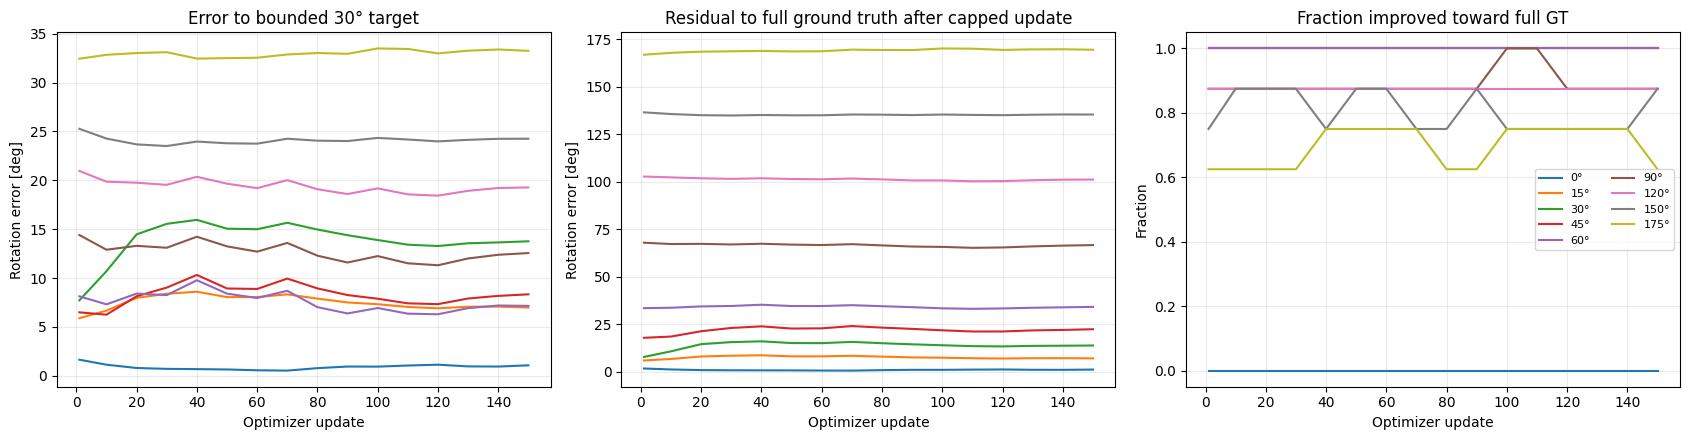

In [18]:
if stochastic_history:
    sh = pd.DataFrame(stochastic_history)
    summary = sh.groupby(["step", "angle_deg"], as_index=False).agg(
        bounded=("error_to_step_cap_deg", "mean"),
        full_gt=("after_cap_full_deg", "mean"),
        before=("before_deg", "mean"),
        improves=("improved_full_cap", "mean"),
    )
    fig, axes = plt.subplots(1, 3, figsize=(17, 4.5))
    for angle, frame in summary.groupby("angle_deg"):
        axes[0].plot(frame.step, frame.bounded, label=f"{angle:g}°")
        axes[1].plot(frame.step, frame.full_gt, label=f"{angle:g}°")
        axes[2].plot(frame.step, frame.improves, label=f"{angle:g}°")
    axes[0].set(title="Error to bounded 30° target", xlabel="Optimizer update", ylabel="Rotation error [deg]")
    axes[1].set(title="Residual to full ground truth after capped update", xlabel="Optimizer update", ylabel="Rotation error [deg]")
    axes[2].set(title="Fraction improved toward full GT", xlabel="Optimizer update", ylabel="Fraction", ylim=(-0.05, 1.05))
    for axis in axes: axis.grid(alpha=0.25)
    axes[2].legend(fontsize=8, ncol=2)
    fig.tight_layout()
    fig.savefig(RUN_DIR / "stochastic_bounded_angular_curves.png", dpi=160, bbox_inches="tight")
    plt.show()
    sh.to_csv(RUN_DIR / "stochastic_bounded_history.csv", index=False)

## 12. Full training and validation with bounded targets only

In [34]:

# ============================================================
# Optimizer and scheduler
# ============================================================

head_params = list(fm_model.head.parameters())
backbone_params = [p for block in (fm_model.transformer_encoder, fm_model.pooler, fm_model.mlp_body) for p in block.parameters()]

assert len({id(p) for p in head_params + backbone_params}) == len(head_params + backbone_params)

optimizer = torch.optim.AdamW([
    {"params": head_params, "lr": HEAD_LEARNING_RATE},
    {"params": backbone_params, "lr": BACKBONE_LEARNING_RATE},
], weight_decay=WEIGHT_DECAY)

scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(
    optimizer, mode="min", factor=LR_REDUCE_FACTOR, patience=LR_REDUCE_STEPS
)


# ============================================================
# Training / validation epoch
# ============================================================

def run_fm55_epoch(loader, *, training, seed, regime="mixed", max_batches=None):
    """Train/evaluate bounded-target FM on real, uncorrupted KAIST streams.

    Every physical window gets a fresh true calibration and sampled prior fault.
    Analytical CTG, on-policy CTG and endpoint losses share the bounded target.
    """
    fm_model.train(training)
    generator = augmentation_generator(seed)
    yaw_randomizer = make_yaw_randomizer(YAW_MAX_DEG, TRAIN_YAW_PROBABILITY if training else VAL_YAW_PROBABILITY)

    totals = defaultdict(float)
    examples = pending_examples = pending_batches = updates = 0
    start = time.perf_counter()

    if training:
        optimizer.zero_grad(set_to_none=True)

    def flush(n):
        if n <= 0:
            raise RuntimeError("Cannot flush zero accumulated samples")

        for p in fm_model.parameters():
            if p.grad is not None:
                p.grad.mul_(1.0 / n)

        torch.nn.utils.clip_grad_norm_(fm_model.parameters(), GRADIENT_CLIP_NORM)
        optimizer.step()
        optimizer.zero_grad(set_to_none=True)

    with (torch.enable_grad() if training else torch.no_grad()):
        for batch_index, cpu_batch in enumerate(loader):
            if max_batches is not None and batch_index >= max_batches:
                break

            base = window_batch_to(cpu_batch, DEVICE, dtype=DTYPE)
            batch_n = len(next(iter(base.current_calibration.values())).transform)

            with torch.no_grad():
                groups = weighted_regime_groups(base, generator, regime)

            for sampled_regime, subgroup in groups:
                with torch.no_grad():
                    calibrated = augment_original_window(subgroup, generator, regime=sampled_regime)

                    if (TRAIN_YAW_PROBABILITY if training else VAL_YAW_PROBABILITY) > 0:
                        calibrated, _ = rotate_yaw_view(calibrated, generator, yaw_randomizer)

                    bounded, statistics = make_bounded_step_training_window(calibrated)

                n = len(next(iter(calibrated.current_calibration.values())).transform)

                loss, _ = joint_flow_endpoint_supervision(
                    bounded, generator=generator, objective=FULL_OBJECTIVE
                )

                importance = regime_loss_multiplier(
                    sampled_regime, regime, FULL_FINE_LOSS_WEIGHT, FULL_COARSE_LOSS_WEIGHT
                )

                if not bool(torch.isfinite(loss.total.detach())):
                    raise FloatingPointError(
                        f"Nonfinite loss for {sampled_regime} batch {batch_index}"
                    )

                if training:
                    (loss.total * n * importance).backward()

                totals["loss"] += float(loss.total.detach()) * n * importance
                totals["endpoint"] += float(loss.endpoint.detach()) * n * importance
                totals["velocity"] += float(loss.velocity.total.detach()) * n * importance
                totals[f"loss_{sampled_regime}"] += float(loss.total.detach()) * n

                for key, stats in statistics.items():
                    totals["fraction_clipped"] += float((stats["fraction"] < 1.0 - 1e-7).sum())
                    totals["num_sensor_targets"] += len(stats["fraction"])

            examples += batch_n

            if training:
                pending_batches += 1
                pending_examples += batch_n

                if pending_batches == GRADIENT_ACCUMULATION_STEPS:
                    flush(pending_examples)
                    updates += 1
                    pending_batches = pending_examples = 0

        if training and pending_batches:
            flush(pending_examples)
            updates += 1

    if not examples:
        raise RuntimeError("No physical windows processed")
    if DEVICE.type == "cuda": torch.cuda.empty_cache()
    return dict(
        loss=totals["loss"] / examples,
        endpoint=totals["endpoint"] / examples,
        velocity=totals["velocity"] / examples,
        fine=totals["loss_fine"] / examples,
        coarse=totals["loss_coarse"] / examples,
        fraction_clipped=totals["fraction_clipped"] / max(totals["num_sensor_targets"], 1),
        num_windows=examples,
        optimizer_steps=updates,
        seconds=time.perf_counter() - start,
    )


# ============================================================
# Fixed bounded-step checkpoint-selection probe
# ============================================================

BEST_PROBE_WINDOWS = 32
BEST_PROBE_BATCH_SIZE = 8
BEST_PROBE_SEED = STOCHASTIC_EVAL_SEED + 500000

# Evaluate only angles in the full training range.
# Include 0 degrees for drift monitoring, but exclude it from the main score.
BEST_PROBE_ANGLES = tuple(
    float(angle) for angle in STOCHASTIC_EVAL_ANGLES_DEG
    if 0.0 <= float(angle) <= FULL_COARSE_MAX_DEG
)

if not any(angle > 0 for angle in BEST_PROBE_ANGLES):
    raise ValueError("Checkpoint probe must contain at least one nonzero fault angle")

if BEST_PROBE_BATCH_SIZE < 1:
    raise ValueError("BEST_PROBE_BATCH_SIZE must be positive")


def build_best_probe_cases():
    """Construct deterministic held-out fault cases once, in memory-safe batches."""
    indices = np.unique(np.linspace(
        0, len(val_dataset) - 1,
        min(BEST_PROBE_WINDOWS, len(val_dataset)),
    ).astype(int))

    batches = []

    for batch_index, start in enumerate(range(0, len(indices), BEST_PROBE_BATCH_SIZE)):
        selection = indices[start:start + BEST_PROBE_BATCH_SIZE]

        cases = make_angular_probe_cases(
            val_dataset,
            selection,
            BEST_PROBE_ANGLES,
            seed=BEST_PROBE_SEED + batch_index,
            keys=STOCHASTIC_FAULT_KEYS,
        )
        batches.append(cases)

    return batches


# The calibration faults, physical windows and augmentation realizations
# remain identical across epochs.
best_probe_batches = build_best_probe_cases()

print(
    f"Checkpoint probe: {sum(len(next(iter(batch.values())).current_calibration[CALIBRATION_KEYS[0]].transform) for batch in best_probe_batches)} "
    f"held-out windows, angles={BEST_PROBE_ANGLES}, "
    f"batch_size={BEST_PROBE_BATCH_SIZE}"
)


@torch.inference_mode()
def evaluate_best_checkpoint_probe(model):
    """Evaluate bounded-step accuracy, full-GT accuracy and zero-fault drift."""
    was_training = model.training
    model.eval()

    try:
        frames = [
            evaluate_bounded_probe(
                model, cases,
                integration_steps=STOCHASTIC_EVAL_INTEGRATION_STEPS,
                cap_deg=MAX_UPDATE_ROTATION_DEG,
            )
            for cases in best_probe_batches
        ]
    finally:
        model.train(was_training)

    data = pd.concat(frames, ignore_index=True)

    summary = summarize_bounded_probe(data)

    in_range = summary.loc[
        (summary["angle_deg"] > 0.0) &
        (summary["angle_deg"] <= FULL_COARSE_MAX_DEG)
    ]

    if in_range.empty:
        raise RuntimeError("No in-range calibration faults in checkpoint probe")

    # Every initial fault angle gets equal weight.
    # Evaluate the correction that will actually be applied at inference.
    bounded_step_deg = float(in_range["mean_cap_to_step"].mean())
    full_gt_deg = float(in_range["mean_cap_to_gt"].mean())

    zero_rows = summary.loc[np.isclose(summary["angle_deg"], 0.0)]
    zero_drift_deg = float(zero_rows["mean_cap_to_gt"].mean()) if len(zero_rows) else float("nan")

    if not np.isfinite(bounded_step_deg):
        raise FloatingPointError("Nonfinite checkpoint-selection score")

    return dict(
        bounded_step_deg=bounded_step_deg,
        full_gt_deg=full_gt_deg,
        zero_drift_deg=zero_drift_deg,
        summary=summary,
    )


# ============================================================
# Checkpoint setup and resume
# ============================================================

history_path = RUN_DIR / "fm55_training_history.csv"
history = []

start_epoch = 0
global_step = 0
best_val = float("inf")
best_epoch = 0

checkpoint_config = dict(
    run_name=RUN_NAME,
    init_mode=INIT_MODE,
    max_update_rotation_deg=MAX_UPDATE_ROTATION_DEG,
    scale_time_offset=BOUNDED_SCALE_TIME_OFFSET_WITH_ROTATION,
    full_coarse_deg=FULL_COARSE_MAX_DEG,
    train_regime=FULL_TRAIN_REGIME,
    fine_coarse_weights=(FULL_FINE_LOSS_WEIGHT, FULL_COARSE_LOSS_WEIGHT),
    objective=FULL_OBJECTIVE,
    train_yaw_probability=TRAIN_YAW_PROBABILITY,
    val_yaw_probability=VAL_YAW_PROBABILITY,
    yaw_max_deg=YAW_MAX_DEG,
    checkpoint_selection=dict(
        metric="mean_cap_to_step",
        angles=BEST_PROBE_ANGLES,
        num_windows=BEST_PROBE_WINDOWS,
        batch_size=BEST_PROBE_BATCH_SIZE,
        seed=BEST_PROBE_SEED,
        integration_steps=STOCHASTIC_EVAL_INTEGRATION_STEPS,
        fault_keys=tuple(STOCHASTIC_FAULT_KEYS),
    ),
)

if RESUME_FULL_TRAINING:
    if not LAST_CHECKPOINT_PATH.is_file():
        raise FileNotFoundError(LAST_CHECKPOINT_PATH)

    saved = torch.load(LAST_CHECKPOINT_PATH, map_location="cpu", weights_only=False)
    extra = saved.get("extra_state") or {}

    if extra.get("bounded_config") != checkpoint_config:
        raise RuntimeError("FM55 configuration or checkpoint-selection settings differ from saved checkpoint")

    load_training_checkpoint(
        LAST_CHECKPOINT_PATH,
        model=fm_model,
        optimizer=optimizer,
        scheduler=scheduler,
        map_location=DEVICE,
        restore_rng_state=True,
    )

    start_epoch = int(saved["epoch"])
    global_step = int(saved["global_step"])
    best_val = float(extra["best_val"])
    best_epoch = int(extra.get("best_epoch", 0))

    if history_path.is_file():
        history = pd.read_csv(history_path).to_dict("records")

    print(f"Resuming FM55 at epoch {start_epoch}; best epoch={best_epoch}, bounded error={best_val:.3f}°")

elif RUN_FULL_TRAINING:
    if BEST_CHECKPOINT_PATH.exists() or LAST_CHECKPOINT_PATH.exists() or history_path.exists():
        raise RuntimeError("Existing FM55 run; set RESUME_FULL_TRAINING=True or choose another RUN_NAME")

    print("Fresh FM55 full run from", INIT_MODE)


def save_fm55(path, epoch, values):
    save_training_checkpoint(
        path,
        model=fm_model,
        optimizer=optimizer,
        scheduler=scheduler,
        epoch=epoch,
        global_step=global_step,
        metrics=values,
        extra_state=dict(
            bounded_config=checkpoint_config,
            best_val=best_val,
            best_epoch=best_epoch,
            source_checkpoint=str(SOURCE_FM_CHECKPOINT),
        ),
    )

Checkpoint probe: 32 held-out windows, angles=(0.0, 15.0, 30.0, 45.0, 60.0, 90.0), batch_size=8
Resuming FM55 at epoch 21; best epoch=21, bounded error=8.724°


In [35]:
if DEVICE.type == "cuda": torch.cuda.empty_cache()

In [36]:



# ============================================================
# Full training
# ============================================================

if RUN_FULL_TRAINING:
    if REQUIRE_STOCHASTIC_IMPROVEMENT and STOCHASTIC_CHECK_PASSED is not True:
        raise RuntimeError("Stochastic probe did not improve the bounded step target")

    for epoch in range(start_epoch, TRAIN_EPOCHS):
        train_shuffle_generator.manual_seed(SEED + 12001 + epoch)

        train = run_fm55_epoch(
            train_loader,
            training=True,
            seed=TRAIN_AUG_SEED + 100003 * epoch,
            regime=FULL_TRAIN_REGIME,
            max_batches=MAX_TRAIN_BATCHES_PER_EPOCH,
        )

        val = run_fm55_epoch(
            val_loader,
            training=False,
            seed=VAL_AUG_SEED,
            regime=FULL_TRAIN_REGIME,
            max_batches=MAX_VAL_BATCHES_PER_EPOCH,
        )

        # Keep the original scheduler behavior.
        scheduler.step(val["loss"])
        global_step += train["optimizer_steps"]

        # Fixed validation cases, evaluated with the inference integrator.
        probe = evaluate_best_checkpoint_probe(fm_model)

        bounded_val_deg = probe["bounded_step_deg"]
        full_gt_val_deg = probe["full_gt_deg"]
        zero_drift_deg = probe["zero_drift_deg"]

        improved = bounded_val_deg < best_val

        if improved:
            best_val = bounded_val_deg
            best_epoch = epoch + 1

        row = dict(
            epoch=epoch + 1,
            global_step=global_step,
            train_loss=train["loss"],
            val_loss=val["loss"],
            train_velocity=train["velocity"],
            train_endpoint=train["endpoint"],
            val_velocity=val["velocity"],
            val_endpoint=val["endpoint"],
            train_fraction_clipped=train["fraction_clipped"],
            val_fraction_clipped=val["fraction_clipped"],
            bounded_val_deg=bounded_val_deg,
            full_gt_val_deg=full_gt_val_deg,
            zero_drift_deg=zero_drift_deg,
            best_bounded_val_deg=best_val,
            head_lr=optimizer.param_groups[0]["lr"],
            backbone_lr=optimizer.param_groups[1]["lr"],
        )

        history.append(row)
        pd.DataFrame(history).to_csv(history_path, index=False)

        if improved:
            save_fm55(BEST_CHECKPOINT_PATH, epoch + 1, {
                "loss": val["loss"],
                "bounded_step_deg": bounded_val_deg,
                "full_gt_deg": full_gt_val_deg,
                "zero_drift_deg": zero_drift_deg,
                **row,
            })

        save_fm55(LAST_CHECKPOINT_PATH, epoch + 1, {
            "loss": val["loss"],
            "bounded_step_deg": bounded_val_deg,
            "full_gt_deg": full_gt_val_deg,
            "zero_drift_deg": zero_drift_deg,
            **row,
        })

        print(
            f"Epoch {epoch+1:3d}/{TRAIN_EPOCHS} "
            f"train={train['loss']:.3f} val={val['loss']:.3f} "
            f"endpoint={val['endpoint']:.3f} "
            f"| bounded={bounded_val_deg:.2f}° "
            f"fullGT={full_gt_val_deg:.2f}° "
            f"zeroDrift={zero_drift_deg:.2f}° "
            f"| best={best_val:.2f}° (epoch {best_epoch}) "
            f"| LR={optimizer.param_groups[0]['lr']:.1e}/{optimizer.param_groups[1]['lr']:.1e}"
            + (" BEST" if improved else ""),
            flush=True,
        )

else:
    print("Full bounded-step training disabled. Set RUN_FULL_TRAINING=True after stochastic preflight.")


Epoch  22/100 train=7.540 val=5.425 endpoint=4.088 | bounded=8.80° fullGT=27.98° zeroDrift=0.97° | best=8.72° (epoch 21) | LR=3.0e-05/3.0e-06
Epoch  23/100 train=7.495 val=5.271 endpoint=3.929 | bounded=8.61° fullGT=27.81° zeroDrift=1.03° | best=8.61° (epoch 23) | LR=3.0e-05/3.0e-06 BEST
Epoch  24/100 train=7.481 val=5.246 endpoint=3.911 | bounded=8.65° fullGT=27.83° zeroDrift=0.94° | best=8.61° (epoch 23) | LR=3.0e-05/3.0e-06
Epoch  25/100 train=7.016 val=5.115 endpoint=3.822 | bounded=8.72° fullGT=27.84° zeroDrift=0.93° | best=8.61° (epoch 23) | LR=3.0e-05/3.0e-06
Epoch  26/100 train=7.189 val=5.157 endpoint=3.921 | bounded=8.81° fullGT=27.93° zeroDrift=0.92° | best=8.61° (epoch 23) | LR=3.0e-05/3.0e-06
Epoch  27/100 train=6.944 val=5.086 endpoint=3.848 | bounded=8.48° fullGT=27.57° zeroDrift=1.00° | best=8.48° (epoch 27) | LR=3.0e-05/3.0e-06 BEST
Epoch  28/100 train=6.870 val=4.974 endpoint=3.744 | bounded=8.52° fullGT=27.69° zeroDrift=1.02° | best=8.48° (epoch 27) | LR=3.0e-05/3.0e

## 13. Full-run learning curves and matched angular evaluation

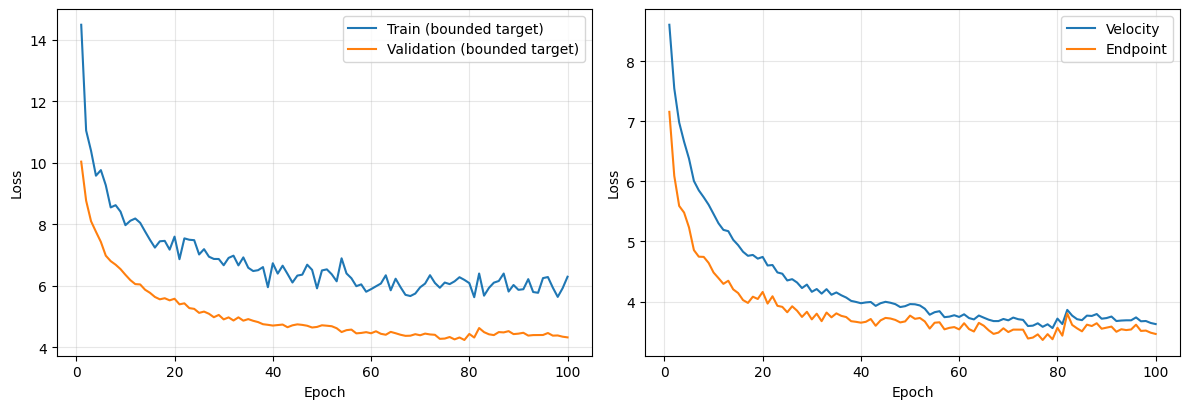

In [ ]:
if history:
    frame = pd.DataFrame(history)
    fig, axes = plt.subplots(1, 2, figsize=(12, 4.2))
    axes[0].plot(frame.epoch, frame.train_loss, label="Train (bounded target)")
    axes[0].plot(frame.epoch, frame.val_loss, label="Validation (bounded target)")
    axes[1].plot(frame.epoch, frame.val_velocity, label="Velocity")
    axes[1].plot(frame.epoch, frame.val_endpoint, label="Endpoint")
    for ax in axes:
        ax.set(xlabel="Epoch", ylabel="Loss")
        ax.grid(alpha=0.3); ax.legend()
    fig.tight_layout()
    fig.savefig(RUN_DIR / "bounded_training_curves.png", dpi=160)
    plt.show()

In [38]:


EVALUATE_BEST_CHECKPOINT = True
if EVALUATE_BEST_CHECKPOINT:
    if not BEST_CHECKPOINT_PATH.is_file(): raise FileNotFoundError(BEST_CHECKPOINT_PATH)
    current = {k: v.detach().cpu().clone() for k, v in fm_model.state_dict().items()}
    load_training_checkpoint(BEST_CHECKPOINT_PATH, model=fm_model, map_location=DEVICE, restore_rng_state=False)
    best_probes = evaluate_bounded_probe(fm_model, probe_cases, integration_steps=FM_INTEGRATION_STEPS)
    display(summarize_bounded_probe(best_probes).round(3))
    best_probes.to_csv(RUN_DIR / "best_angular_probe.csv", index=False)
    fm_model.load_state_dict(current, strict=True)
    del current

,angle_deg,n,mean_before,oracle_remaining,mean_raw_to_step,mean_cap_to_step,mean_raw_to_gt,mean_cap_to_gt,mean_raw_step,mean_direction_cosine,fraction_improving_raw,fraction_improving_cap
0,0.0,8,0.0,0.0,2.234,2.234,2.234,2.234,2.234,NaN,0.000,0.000
1,15.0,8,15.0,0.0,6.208,6.208,6.208,6.208,16.754,0.913,0.875,0.875
2,30.0,8,30.0,0.0,8.093,8.093,8.093,8.093,25.375,0.965,1.000,1.000
3,45.0,8,45.0,15.0,4.716,4.676,17.143,17.291,29.067,0.984,1.000,1.000
4,60.0,8,60.0,30.0,4.879,4.736,31.147,31.656,29.647,0.984,1.000,1.000
5,90.0,8,90.0,60.0,11.946,11.828,65.941,66.389,29.235,0.833,0.875,0.875
6,120.0,8,120.0,90.0,19.883,18.423,98.367,100.727,32.421,0.675,0.875,0.875
7,150.0,8,150.0,120.0,31.206,25.346,129.737,136.492,38.374,0.469,0.750,0.750
8,175.0,8,175.0,145.0,38.552,35.418,169.034,169.555,32.327,0.226,0.500,0.500


## 14. Interpretation

**Success criterion:** accuracy **to the intermediate bounded target** improves without destroying progress toward the original full GT. When an initial fault is 150°, a perfectly correct 30° update still leaves approximately 120° residual. A full-GT residual near 120° is therefore *expected*, not a failed endpoint loss.

Before claiming large-angle convergence, run a separate **chronological feedback rollout** on held-out KAIST sequences using `cap_predicted_se3_step()` at each physical window. This notebook evaluates one-step learned bounded corrections; it does not claim to solve multi-window observability or New College transfer. All observed motion remains real.

**Comparing against FM52:** use identical initial prior faults and physical validation windows; do not compare FM55's bounded-target loss directly against FM52's full-GT training loss. Report both error to the step target and true-GT residual.

## Notebook 55 evaluation appendix: FM53 vs FM55
Append these two code cells after the completed Notebook 55 setup/training cells. The cells use existing imports and helpers (window_batch_to, topology_slice_batch, model_predictions, make_angular_probe_cases, evaluate_bounded_probe, etc.). No model weights are changed; both models are loaded from disk into separate inference models.

The first cell uses consecutive real KAIST windows, fixed true extrinsics across a sequence, a single injected initial fault, and four independent feedback hypotheses: FM53 raw, FM53 capped, FM55 raw, FM55 capped. The second cell compares rotation magnitudes and directions on the same physical windows and faults, without feedback.

Choose the FM53 reference checkpoint explicitly. The default uses FM53 legacy best.pt; switch to SOURCE_FM_CHECKPOINT to compare the uncorrupted FM52 model instead. Validation is the default split.

Important: The 30° inference cap is only a diagnostic ablation, not a proposed fix for poor large-angle direction learning. roll55_df and direction55_df are saved as CSV along with plots.

FM53: /home/camel/Skoltech/Mobile_Robotics_Lab/nn-obs-calib/runs/kaist_pooled_calibration_fm.11_three_stage_full/best.pt
FM55: /home/camel/Skoltech/Mobile_Robotics_Lab/nn-obs-calib/runs/kaist_pooled_calibration_fm.12_bounded_step_30deg/best.pt
Completed Urban26 start=0: 364 rows


,fault_key,method,initial_deg,final_active_deg,final_healthy_deg,last_step_deg,final_translation_cm,final_tau_ms,improvement_deg
0,lidar,FM53 cap,0.0,7.52,5.76,0.71,21.48,2.98,-7.52
1,lidar,FM53 cap,30.0,9.25,5.33,1.20,27.72,2.47,20.75
2,lidar,FM53 cap,60.0,8.63,5.50,0.96,24.49,3.58,51.37
3,lidar,FM53 cap,90.0,11.71,3.13,1.34,29.07,4.02,78.29
4,lidar,FM53 cap,120.0,15.42,1.22,1.33,31.42,4.92,104.58
5,lidar,FM53 cap,150.0,27.62,0.77,1.03,45.30,4.37,122.38
6,lidar,FM53 cap,175.0,167.63,1.62,11.87,382.51,8.65,7.37
7,lidar,FM53 raw,0.0,7.52,5.76,0.71,21.48,2.98,-7.52
8,lidar,FM53 raw,30.0,8.20,5.91,1.19,26.11,0.44,21.80
9,lidar,FM53 raw,60.0,8.61,5.69,1.16,27.82,0.48,51.39


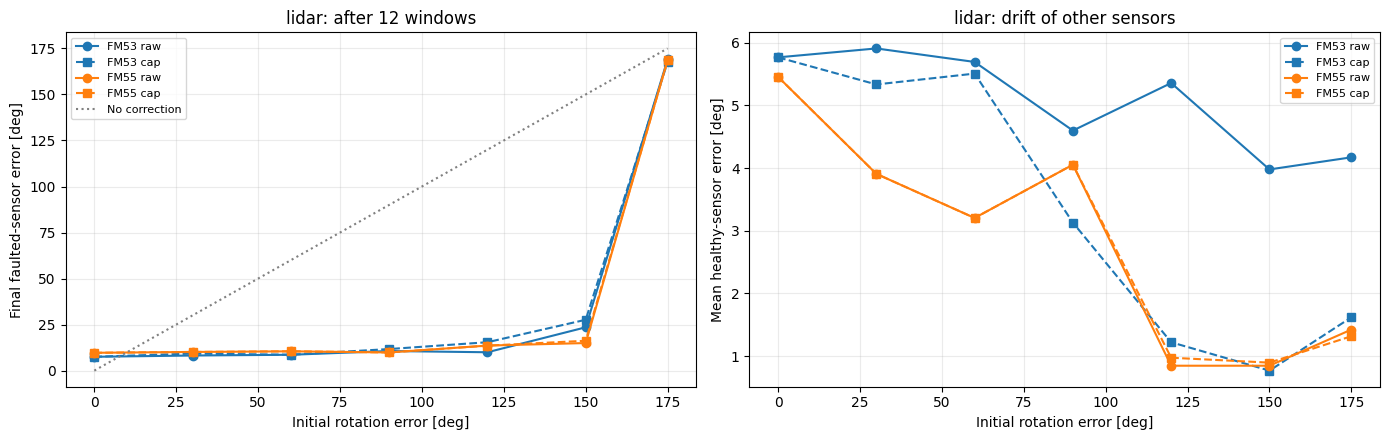

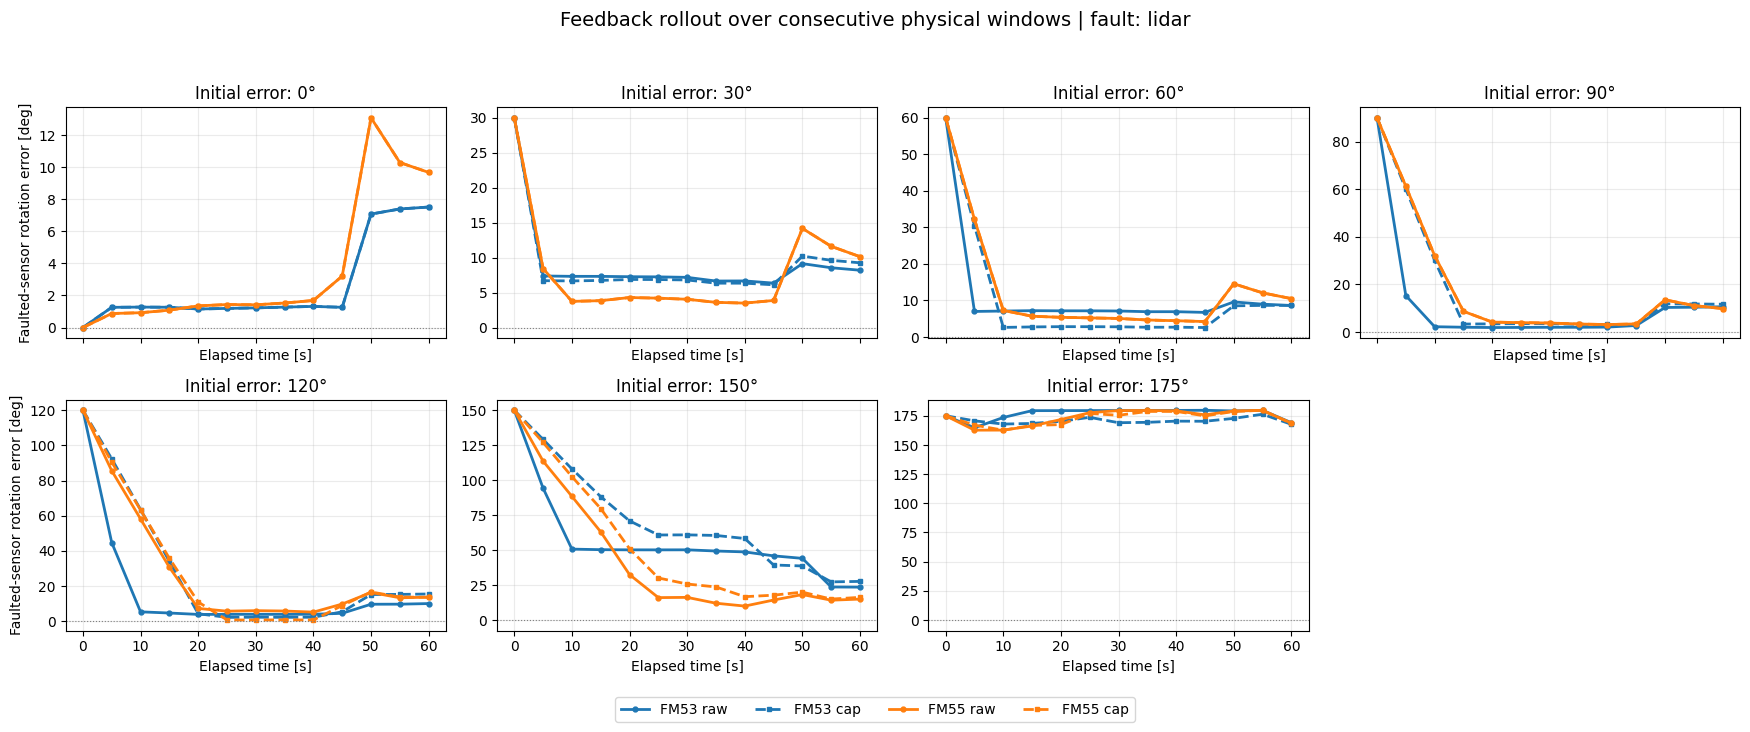

Saved rollout tables and figures in /home/camel/Skoltech/Mobile_Robotics_Lab/nn-obs-calib/runs/kaist_pooled_calibration_fm.12_bounded_step_30deg/plots/fm53_fm55_comparison


In [41]:
# CELL 1. Consecutive-window feedback rollouts: FM53/FM55, raw/capped.
# Run after Notebook 55 setup/helper cells. This is inference only.
from dataclasses import replace
from pathlib import Path

from obscalib.geometry.lie import se3_exp, se3_log

ROLL55_FM53_CHECKPOINT = ROOT / "runs" / "kaist_pooled_calibration_fm.11_three_stage_full" / "best.pt"
ROLL55_FM55_CHECKPOINT = BEST_CHECKPOINT_PATH
# To compare against the original non-corruption FM52 model, instead set:
# ROLL55_FM53_CHECKPOINT = SOURCE_FM_CHECKPOINT
ROLL55_SPLIT = "validation"        # "test" only when ready for final untouched test evaluation
ROLL55_SEQUENCE_NAMES = (VAL_NAMES[0],)  # Smoke test. For full: tuple(VAL_NAMES)
ROLL55_NUM_WINDOWS = 12           # 12 x 5s = 60s
ROLL55_STARTS_PER_SEQUENCE = 1   # Increase to 2-3 for the full comparison
ROLL55_AXIS_SEEDS = 1            # Increase to 3 for different rotation axes
ROLL55_FAULT_KEYS = ("lidar",)   # Full: ("lidar", "lidar_right")
ROLL55_ANGLES_DEG = (0.0, 30.0, 60.0, 90.0, 120.0, 150.0, 175.0)
ROLL55_CAP_DEG = float(MAX_UPDATE_ROTATION_DEG)
ROLL55_INTEGRATION_STEPS = FM_INTEGRATION_STEPS
ROLL55_UPDATE_ALL_KEYS = True     # False: oracle-isolate the faulted LiDAR; True: assess healthy-sensor drift too
ROLL55_SEED = VAL_AUG_SEED + 1800000
ROLL55_SHOW_PLOTS = True
ROLL55_OUTPUT_DIR = RUN_DIR / "plots" / "fm53_fm55_comparison"
ROLL55_OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

assert ROLL55_NUM_WINDOWS >= 2
assert tuple(CALIBRATION_KEYS) == ("imu", "lidar", "lidar_right")
assert all(0.0 <= a < 180.0 for a in ROLL55_ANGLES_DEG)
assert set(ROLL55_FAULT_KEYS).issubset(set(CALIBRATION_KEYS))


def roll55_load_models():
    """Load both trained checkpoints into independent, inference-only models."""
    paths = {"FM53": Path(ROLL55_FM53_CHECKPOINT), "FM55": Path(ROLL55_FM55_CHECKPOINT)}
    loaded = {}
    for name, path in paths.items():
        if not path.is_file():
            raise FileNotFoundError(f"{name} checkpoint not found: {path}")
        model = PooledCalibrationFlowModel(flow_config.backbone, **flow_config.model_kwargs()).to(device=DEVICE, dtype=DTYPE)
        load_training_checkpoint(path, model=model, map_location=DEVICE, restore_rng_state=False)
        model.eval().requires_grad_(False)
        loaded[name] = model
        print(f"{name}: {path}")
    return loaded


@torch.inference_mode()
def roll55_rotation_error_deg(estimate, reference):
    """Stable SO(3) geodesic angle in degrees, including near 180 degrees."""
    R = reference[..., :3, :3] @ estimate[..., :3, :3].transpose(-1, -2)
    skew = torch.stack((R[..., 2, 1]-R[..., 1, 2], R[..., 0, 2]-R[..., 2, 0], R[..., 1, 0]-R[..., 0, 1]), dim=-1)
    return torch.rad2deg(torch.atan2(0.5*torch.linalg.vector_norm(skew, dim=-1), 0.5*(R.diagonal(dim1=-2, dim2=-1).sum(dim=-1)-1)))


def roll55_clone_states(states):
    return {key: replace(s, transform=s.transform.detach().clone(), time_offset=s.time_offset.detach().clone()) for key, s in states.items()}


def roll55_sequence_starts(dataset, sequence):
    indices = np.asarray(dataset.window_indices_for_sequence(sequence), dtype=np.int64)
    max_start = len(indices) - ROLL55_NUM_WINDOWS
    if max_start < 0:
        raise ValueError(f"{sequence}: {len(indices)} windows, need {ROLL55_NUM_WINDOWS}")
    starts = np.unique(np.linspace(0, max_start, min(ROLL55_STARTS_PER_SEQUENCE, max_start+1)).round().astype(int))
    return indices, starts


def roll55_load_chronological_windows(dataset, sequence_indices, start):
    """Unmodified real sensor windows. Preserve one constant GT calibration for the whole rollout."""
    chosen = sequence_indices[int(start):int(start)+ROLL55_NUM_WINDOWS]
    windows = [window_batch_to(collate_windows([dataset[int(i)]]), DEVICE, dtype=DTYPE) for i in chosen]
    truth = roll55_clone_states(windows[0].current_calibration)
    for window in windows[1:]:
        for key in truth:
            torch.testing.assert_close(window.current_calibration[key].transform, truth[key].transform, atol=2e-5, rtol=2e-5)
            torch.testing.assert_close(window.current_calibration[key].time_offset, truth[key].time_offset, atol=2e-6, rtol=2e-6)
    return chosen, windows, truth


def roll55_build_cases(sequence_index, start):
    """Same injected axes/angles for every model and for raw/cap variants."""
    cases = []
    for key in ROLL55_FAULT_KEYS:
        for axis_id in range(ROLL55_AXIS_SEEDS):
            seed = ROLL55_SEED + sequence_index*100003 + int(start)*1069 + CALIBRATION_KEYS.index(key)*227 + axis_id
            axis = np.random.default_rng(seed).normal(size=3)
            axis = axis / np.linalg.norm(axis)
            for angle in ROLL55_ANGLES_DEG:
                cases.append(dict(fault_key=key, axis_id=axis_id, initial_deg=float(angle), axis=axis))
    return cases


def roll55_initial_states(truth, cases):
    """Apply a rotation-only left SE(3) prior fault once, matching the angular probe convention."""
    n = len(cases)
    duplicated = {key: replace(state, transform=state.transform.expand(n,-1,-1).clone(),
                               time_offset=state.time_offset.expand(n,*state.time_offset.shape[1:]).clone()) for key,state in truth.items()}
    template = next(iter(duplicated.values())).transform
    xi = {key: torch.zeros((n,6), dtype=template.dtype, device=template.device) for key in duplicated}
    tau = {key: torch.zeros_like(state.time_offset) for key,state in duplicated.items()}
    for i, case in enumerate(cases):
        xi[case["fault_key"]][i,:3] = torch.as_tensor(case["axis"], device=template.device, dtype=template.dtype) * np.deg2rad(case["initial_deg"])
    prior = apply_prior_perturbation(duplicated, xi, tau)
    for i, case in enumerate(cases):
        measured = roll55_rotation_error_deg(prior[case["fault_key"]].transform[i:i+1], duplicated[case["fault_key"]].transform[i:i+1]).item()
        if abs(measured-case["initial_deg"]) > 0.06:
            raise AssertionError(f"Incorrect injected angle: {measured} vs {case['initial_deg']}")
    return prior


def roll55_step(states, output, cases, *, capped):
    """Update each hypothesis independently. Clip full SE(3) twist, not isolated SO(3) only."""
    updated = {}
    n = len(cases)
    keys_to_update = [c["fault_key"] for c in cases]
    raw_sizes, applied_sizes = {}, {}
    for key, state in states.items():
        raw_xi = output.predictions[key].delta_xi
        xi = cap_predicted_se3_step(raw_xi, cap_deg=ROLL55_CAP_DEG) if capped else raw_xi
        tau = output.predictions[key].delta_tau
        if not ROLL55_UPDATE_ALL_KEYS:
            allowed = torch.tensor([k==key for k in keys_to_update], device=xi.device, dtype=torch.bool)
            xi = torch.where(allowed[:,None], xi, torch.zeros_like(xi))
            tau = torch.where(allowed.reshape(n,*([1]*(tau.ndim-1))), tau, torch.zeros_like(tau))
        transform = se3_exp(xi) @ state.transform
        updated[key] = replace(state, transform=transform, time_offset=state.time_offset+tau)
        raw_sizes[key] = torch.rad2deg(torch.linalg.vector_norm(raw_xi[:,:3],dim=-1))
        applied_sizes[key] = torch.rad2deg(torch.linalg.vector_norm(xi[:,:3],dim=-1))
    return updated, raw_sizes, applied_sizes


def roll55_record(states, truth, cases, label, sequence, start, step, window_index, raw_sizes=None, applied_sizes=None):
    """Return one vectorized snapshot of active and healthy rotation errors."""
    keys = tuple(truth)
    error = torch.stack([roll55_rotation_error_deg(states[k].transform, truth[k].transform) for k in keys], dim=1)
    index = torch.tensor([keys.index(c["fault_key"]) for c in cases], device=error.device)
    n = len(cases)
    active = error[torch.arange(n,device=error.device),index]
    healthy = (error.sum(dim=1)-active)/(len(keys)-1)
    trans = torch.stack([100.0*torch.linalg.vector_norm(states[k].transform[...,:3,3]-truth[k].transform[...,:3,3],dim=-1) for k in keys],dim=1)
    tau_error = torch.stack([1000.0*(states[k].time_offset-truth[k].time_offset).abs().reshape(n,-1).mean(dim=1) for k in keys],dim=1)
    active_trans = trans[torch.arange(n,device=error.device),index]
    active_tau = tau_error[torch.arange(n,device=error.device),index]
    zeros = torch.zeros_like(active)
    raw_step = zeros if raw_sizes is None else torch.stack([raw_sizes[c["fault_key"]][i] for i,c in enumerate(cases)])
    applied_step = zeros if applied_sizes is None else torch.stack([applied_sizes[c["fault_key"]][i] for i,c in enumerate(cases)])
    values = torch.stack((active,healthy,raw_step,applied_step,active_trans,active_tau),dim=1).detach().cpu().numpy()
    return [dict(method=label, model=label.split()[0], capped="cap" in label,
                 sequence=sequence, start=int(start),
                 fault_key=case["fault_key"],axis_id=case["axis_id"], initial_deg=case["initial_deg"],
                 step=int(step), time_s=float(step*WINDOW_DURATION_S),window_index=int(window_index),
                 active_error_deg=float(values[i,0]), healthy_error_deg=float(values[i,1]),
                 raw_step_deg=float(values[i,2]),applied_step_deg=float(values[i,3]),
                 active_translation_error_cm=float(values[i,4]),active_tau_error_ms=float(values[i,5])) for i,case in enumerate(cases)]


@torch.inference_mode()
def roll55_evaluate_one_sequence(models, dataset, sequence, sequence_index, start):
    indices, _ = roll55_sequence_starts(dataset, sequence)
    selected, windows, truth = roll55_load_chronological_windows(dataset, indices, start)
    cases = roll55_build_cases(sequence_index, start)
    initial = roll55_initial_states(truth, cases)
    variants = [(name,capped) for name in models for capped in (False, True)]
    states = {(name,capped): roll55_clone_states(initial) for name,capped in variants}
    duplicate_indices = torch.zeros(len(cases),device=DEVICE,dtype=torch.long)
    shared_windows = [topology_slice_batch(window, duplicate_indices) for window in windows]
    rows=[]
    for name,capped in variants:
        label=f"{name} {'cap' if capped else 'raw'}"
        rows.extend(roll55_record(states[(name,capped)], truth, cases, label, sequence, start, 0, -1))
    for step,(index,window) in enumerate(zip(selected,shared_windows),1):
        for name,capped in variants:
            current = states[(name,capped)]
            hypothesis = clone_with_current_calibration(window,current)
            output = model_predictions(models[name],hypothesis,steps=ROLL55_INTEGRATION_STEPS)
            updated,raw_sizes,applied_sizes = roll55_step(current,output,cases,capped=capped)
            states[(name,capped)] = updated
            label=f"{name} {'cap' if capped else 'raw'}"
            rows.extend(roll55_record(updated,truth,cases,label,sequence,start,step,index,raw_sizes,applied_sizes))
    return rows


roll55_models = roll55_load_models()
roll55_dataset = val_dataset if ROLL55_SPLIT == "validation" else test_dataset
roll55_trajectories=[]
for seq_idx,roll55_current_sequence in enumerate(ROLL55_SEQUENCE_NAMES):
    positions,starts = roll55_sequence_starts(roll55_dataset,roll55_current_sequence)
    for roll55_current_start in starts:
        roll55_trajectories.extend(roll55_evaluate_one_sequence(roll55_models,roll55_dataset,roll55_current_sequence,seq_idx,int(roll55_current_start)))
        print(f"Completed {roll55_current_sequence} start={roll55_current_start}: {len(roll55_trajectories)} rows",flush=True)
roll55_df=pd.DataFrame(roll55_trajectories)
if not np.isfinite(roll55_df[["active_error_deg","healthy_error_deg","raw_step_deg","applied_step_deg","active_translation_error_cm","active_tau_error_ms"]].to_numpy()).all():
    raise FloatingPointError("Nonfinite rollout result")
roll55_df.to_csv(ROLL55_OUTPUT_DIR/"rollout_4_methods.csv",index=False)
roll55_final=roll55_df[roll55_df.step==ROLL55_NUM_WINDOWS].groupby(["fault_key","method","initial_deg"],as_index=False).agg(
    final_active_deg=("active_error_deg","mean"),final_healthy_deg=("healthy_error_deg","mean"),
    last_step_deg=("applied_step_deg","mean"),
    final_translation_cm=("active_translation_error_cm","mean"),final_tau_ms=("active_tau_error_ms","mean"))
roll55_final["improvement_deg"]=roll55_final["initial_deg"]-roll55_final["final_active_deg"]
roll55_final.to_csv(ROLL55_OUTPUT_DIR/"rollout_4_methods_final.csv",index=False)
display(roll55_final.round(2))

# Method identity is color; raw versus capped is line style, in every figure.
roll55_styles = {
    "FM53 raw": dict(color="tab:blue", linestyle="-", marker="o"),
    "FM53 cap": dict(color="tab:blue", linestyle="--", marker="s"),
    "FM55 raw": dict(color="tab:orange", linestyle="-", marker="o"),
    "FM55 cap": dict(color="tab:orange", linestyle="--", marker="s"),
}
roll55_method_order = tuple(roll55_styles)

for fault_key, fault_df in roll55_df.groupby("fault_key", sort=False):
    # Figure 1: summary after ALL windows. Don't mix fault types in the full run.
    fault_final = roll55_final.loc[roll55_final.fault_key == fault_key]
    fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))
    for method in roll55_method_order:
        sub = fault_final.loc[fault_final.method == method].sort_values("initial_deg")
        if sub.empty:
            continue
        style = roll55_styles[method]
        axes[0].plot(sub.initial_deg, sub.final_active_deg, label=method, **style)
        axes[1].plot(sub.initial_deg, sub.final_healthy_deg, label=method, **style)
    angles = np.sort(fault_final.initial_deg.unique())
    axes[0].plot(angles, angles, color="gray", linestyle=":", label="No correction")
    axes[0].set(xlabel="Initial rotation error [deg]", ylabel="Final faulted-sensor error [deg]",
                title=f"{fault_key}: after {ROLL55_NUM_WINDOWS} windows")
    axes[1].set(xlabel="Initial rotation error [deg]", ylabel="Mean healthy-sensor error [deg]",
                title=f"{fault_key}: drift of other sensors")
    for ax in axes:
        ax.grid(alpha=0.25)
        ax.legend(fontsize=8)
    fig.tight_layout()
    fig.savefig(ROLL55_OUTPUT_DIR / f"rollout_4_methods_final_{fault_key}.png", dpi=160, bbox_inches="tight")
    if ROLL55_SHOW_PLOTS:
        plt.show()
    else:
        plt.close(fig)

    # Figure 2: EVERY initial angle gets its own time-series panel, with ALL FOUR methods.
    # Time zero is the injected prior; t>0 is the state after processing each real window.
    angles = np.sort(fault_df.initial_deg.unique())
    ncols = min(4, len(angles))
    nrows = int(np.ceil(len(angles) / ncols))
    fig, axes = plt.subplots(nrows, ncols, figsize=(4.4 * ncols, 3.65 * nrows), squeeze=False, sharex=True)
    flat_axes = axes.ravel()
    for panel, angle in enumerate(angles):
        ax = flat_axes[panel]
        angle_df = fault_df.loc[np.isclose(fault_df.initial_deg, angle)]
        for method in roll55_method_order:
            method_df = angle_df.loc[angle_df.method == method]
            if method_df.empty:
                continue
            grouped = method_df.groupby("time_s")["active_error_deg"]
            stats = grouped.agg(["mean", "count"]).sort_index()
            times = stats.index.to_numpy(dtype=float)
            means = stats["mean"].to_numpy(dtype=float)
            style = roll55_styles[method]
            ax.plot(times, means, label=method, color=style["color"], linestyle=style["linestyle"],
                    linewidth=2, marker=style["marker"], markersize=3.5)
            # IQR reflects variation across sequences/starts/axes when multiple cases exist.
            if stats["count"].max() > 1:
                quantiles = grouped.quantile([0.25, 0.75]).unstack().sort_index()
                ax.fill_between(quantiles.index.to_numpy(dtype=float), quantiles[0.25].to_numpy(dtype=float),
                                quantiles[0.75].to_numpy(dtype=float), color=style["color"], alpha=0.10)
        ax.axhline(0, color="gray", linewidth=0.8, linestyle=":")
        ax.set(title=f"Initial error: {angle:g}°", xlabel="Elapsed time [s]")
        if panel % ncols == 0:
            ax.set_ylabel("Faulted-sensor rotation error [deg]")
        ax.grid(alpha=0.25)
    for unused in flat_axes[len(angles):]:
        unused.set_visible(False)
    handles, labels = flat_axes[0].get_legend_handles_labels()
    fig.legend(handles, labels, loc="lower center", ncol=4, fontsize=10, bbox_to_anchor=(0.5, 0.01))
    fig.suptitle(f"Feedback rollout over consecutive physical windows | fault: {fault_key}", fontsize=14, y=0.995)
    fig.tight_layout(rect=(0, 0.065, 1, 0.96))
    fig.savefig(ROLL55_OUTPUT_DIR / f"rollout_4_methods_by_angle_{fault_key}.png", dpi=170, bbox_inches="tight")
    if ROLL55_SHOW_PLOTS:
        plt.show()
    else:
        plt.close(fig)

print("Saved rollout tables and figures in", ROLL55_OUTPUT_DIR)

## Matched one-step predictions
The direction cosine uses the principal SO(3) logarithm of the full GT correction and the uncapped predicted rotation vector. Compare magnitudes and cosines before considering any clipping. The fixed angular probes are re-created once per batch/seed and reused between both models.

,model,angle_deg,n,predicted_step_deg,capped_step_deg,direction_cosine,after_raw_gt_deg,after_cap_gt_deg,error_to_bounded_step_deg,fraction_improving
0,FM53,0.0,64,0.778,0.778,NaN,0.778,0.778,0.778,0.000
1,FM53,15.0,64,12.313,12.313,0.889,5.391,5.391,5.391,0.969
2,FM53,30.0,64,26.786,26.103,0.969,7.380,7.050,7.050,1.000
3,FM53,45.0,64,40.960,28.773,0.977,9.014,17.471,5.181,1.000
4,FM53,60.0,64,51.985,28.952,0.969,13.416,32.234,5.857,1.000
5,FM53,90.0,64,60.188,29.132,0.816,45.571,67.365,15.036,0.984
6,FM53,120.0,64,70.028,29.306,0.293,101.391,112.389,30.917,0.625
7,FM53,150.0,64,69.913,29.723,0.170,137.455,145.697,36.077,0.625
8,FM53,175.0,64,64.047,29.243,0.048,168.679,172.455,40.149,0.547
9,FM55,0.0,64,1.201,1.201,NaN,1.201,1.201,1.201,0.000


cosine_gain_fm55        step_difference_deg          \
                      mean median                mean  median   
angle_deg                                                       
0.0                    NaN    NaN               0.423   0.123   
15.0                 0.015  0.005               2.358   2.400   
30.0                 0.003  0.000              -3.234  -3.795   
45.0                 0.001  0.000             -13.299 -15.051   
60.0                 0.003  0.002             -23.131 -25.163   
90.0                 0.057  0.029             -32.672 -37.872   
120.0               -0.025 -0.018             -40.080 -44.477   
150.0               -0.028 -0.050             -36.728 -37.694   
175.0                0.006 -0.007             -31.066 -31.449   

          raw_error_gain_fm55_deg          
                             mean  median  
angle_deg                                  
0.0                        -0.423  -0.123  
15.0                        0.161  -0.120  
30.0                       -0.772  -1.130  
45.0                       -9.283 -10.448  
60.0                      -18.555 -20.877  
90.0                      -20.540 -23.971  
120.0                     -11.078 -15.008  
150.0                      -6.361  -5.233  
175.0                      -2.704  -2.327

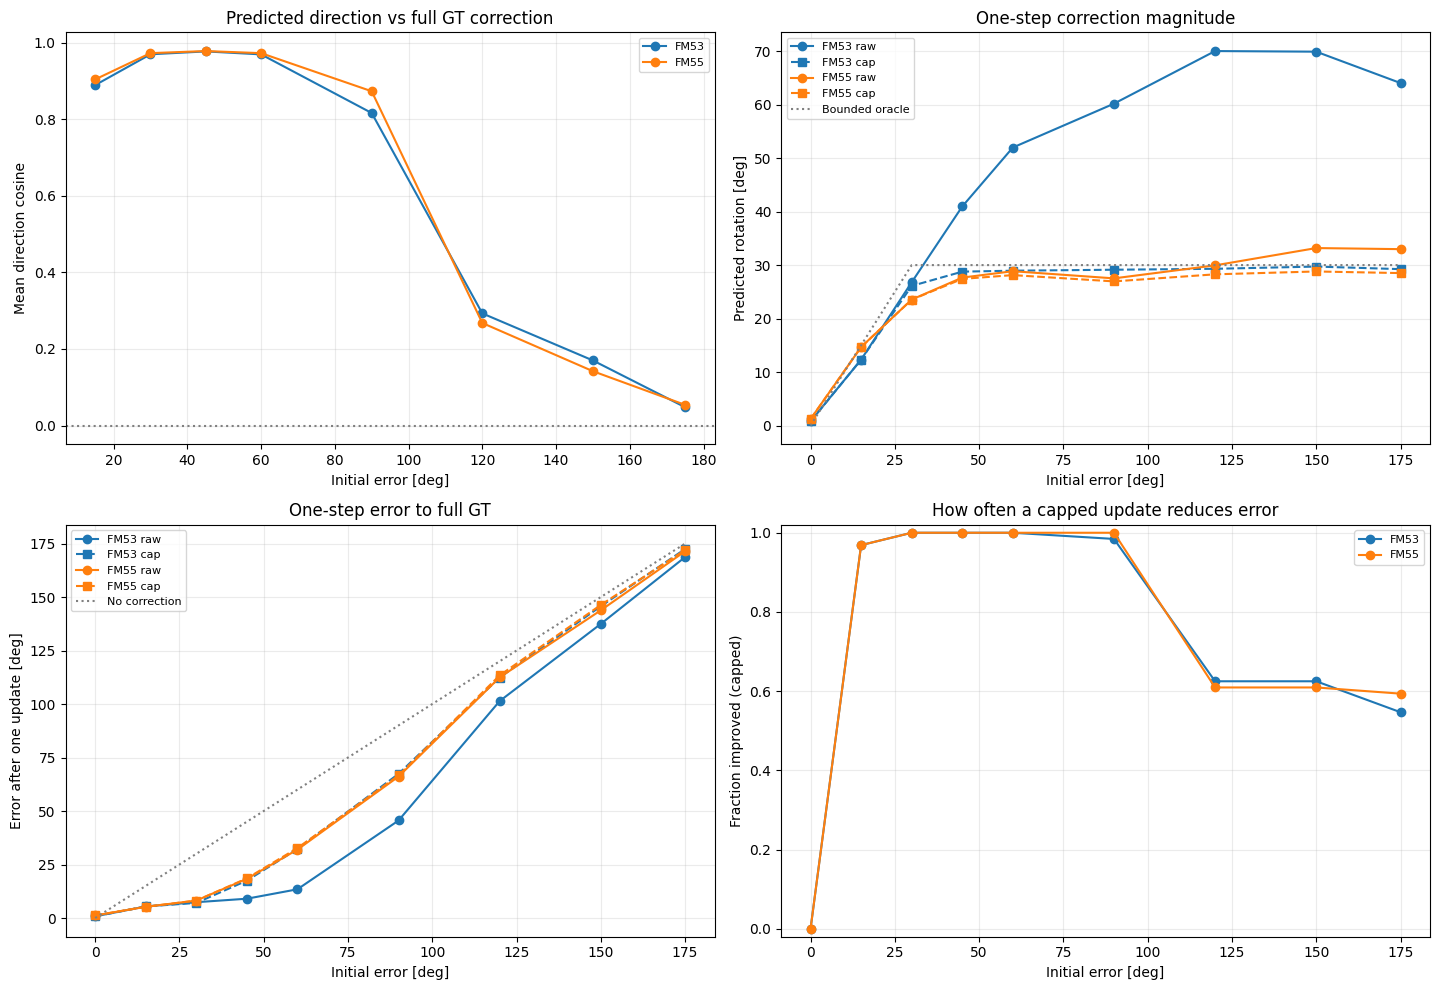

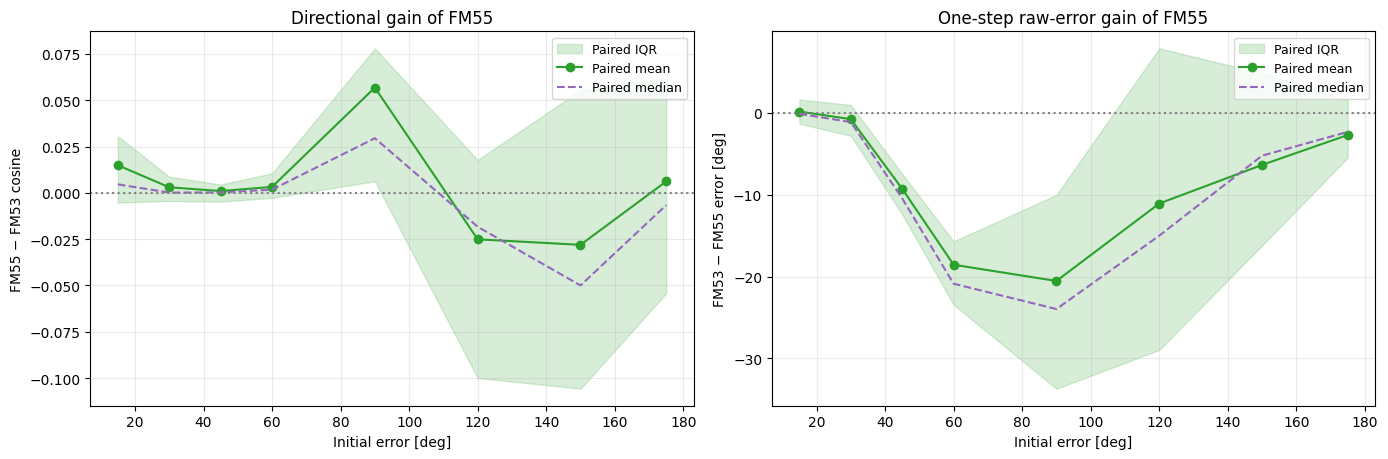

Saved direction/magnitude tables and figures in /home/camel/Skoltech/Mobile_Robotics_Lab/nn-obs-calib/runs/kaist_pooled_calibration_fm.12_bounded_step_30deg/plots/fm53_fm55_comparison


In [42]:
# CELL 2. Paired direction/magnitude predictions on EXACTLY the same physical windows and faults.
# Does not apply feedback, change either model, or simulate sensor measurements.
DIRECTION55_SPLIT = "validation"   # Keep test untouched until final comparison
DIRECTION55_WINDOWS = 32           # Increase to 64/128 after smoke test
DIRECTION55_BATCH_SIZE = 8         # Actual GPU batch size
DIRECTION55_AXIS_SEEDS = 2         # Independent axes, reused between both models
DIRECTION55_ANGLES_DEG = (0.0, 15.0, 30.0, 45.0, 60.0, 90.0, 120.0, 150.0, 175.0)
DIRECTION55_SEED = VAL_AUG_SEED + 1900000
DIRECTION55_SHOW_PLOTS = True

direction55_dataset = val_dataset if DIRECTION55_SPLIT == "validation" else test_dataset
direction55_indices = np.unique(np.linspace(0, len(direction55_dataset)-1,
                                           min(DIRECTION55_WINDOWS, len(direction55_dataset))).astype(int))
direction55_rows = []
for axis_id in range(DIRECTION55_AXIS_SEEDS):
    for group_index, start in enumerate(range(0, len(direction55_indices), DIRECTION55_BATCH_SIZE)):
        selected = direction55_indices[start:start+DIRECTION55_BATCH_SIZE]
        cases = make_angular_probe_cases(direction55_dataset, selected, DIRECTION55_ANGLES_DEG,
                                         seed=DIRECTION55_SEED + axis_id*100003 + group_index,
                                         keys=STOCHASTIC_FAULT_KEYS)
        # Build cases ONCE for both models: same raw streams, physical GT, axes and injected priors.
        for label, model in roll55_models.items():
            frame = evaluate_bounded_probe(model, cases, integration_steps=ROLL55_INTEGRATION_STEPS, cap_deg=ROLL55_CAP_DEG)
            frame["model"] = label
            frame["axis_seed"] = axis_id
            frame["physical_index"] = [int(selected[j]) for j in frame.window_index]
            direction55_rows.append(frame)

direction55_df = pd.concat(direction55_rows, ignore_index=True)
direction55_df.to_csv(ROLL55_OUTPUT_DIR / "paired_directions_raw.csv", index=False)

# Direction cosine refers to UNcapped predicted rotation toward FULL true correction.
# At 0 degrees the true correction direction is undefined: exclude 0° from cosine charts.
direction55_summary = direction55_df.groupby(["model", "angle_deg"], as_index=False).agg(
    n=("raw_step_deg", "size"), predicted_step_deg=("raw_step_deg", "mean"),
    capped_step_deg=("capped_step_deg", "mean"), direction_cosine=("direction_cosine", "mean"),
    after_raw_gt_deg=("after_raw_full_deg", "mean"), after_cap_gt_deg=("after_cap_full_deg", "mean"),
    error_to_bounded_step_deg=("error_to_step_cap_deg", "mean"),
    fraction_improving=("improved_full_cap", "mean"))
direction55_summary.to_csv(ROLL55_OUTPUT_DIR / "paired_directions_summary.csv", index=False)
display(direction55_summary.round(3))

# Casewise matched comparison rather than a comparison of unpaired averages.
join_keys = ["physical_index", "axis_seed", "angle_deg", "key"]
a = direction55_df.loc[direction55_df.model == "FM53", join_keys + ["raw_step_deg", "direction_cosine", "after_raw_full_deg"]]
b = direction55_df.loc[direction55_df.model == "FM55", join_keys + ["raw_step_deg", "direction_cosine", "after_raw_full_deg"]]
direction55_paired = a.merge(b, on=join_keys, suffixes=("_fm53", "_fm55"), validate="one_to_one")
if len(direction55_paired) != len(a) or len(a) != len(b):
    raise RuntimeError("Paired comparison lost cases")
direction55_paired["cosine_gain_fm55"] = direction55_paired.direction_cosine_fm55 - direction55_paired.direction_cosine_fm53
direction55_paired["step_difference_deg"] = direction55_paired.raw_step_deg_fm55 - direction55_paired.raw_step_deg_fm53
direction55_paired["raw_error_gain_fm55_deg"] = direction55_paired.after_raw_full_deg_fm53 - direction55_paired.after_raw_full_deg_fm55
direction55_paired.to_csv(ROLL55_OUTPUT_DIR / "paired_directions_casewise.csv", index=False)
display(direction55_paired.groupby("angle_deg")[["cosine_gain_fm55", "step_difference_deg", "raw_error_gain_fm55_deg"]]
        .agg(["mean", "median"]).round(3))

# Figure 1: model-level diagnostics. FM53/FM55 are colors, raw/cap are line styles.
direction55_colors = {"FM53": "tab:blue", "FM55": "tab:orange"}
fig, axes = plt.subplots(2, 2, figsize=(14.5, 10))
for label, sub in direction55_summary.groupby("model", sort=False):
    sub = sub.sort_values("angle_deg")
    color = direction55_colors[label]
    positive = sub.loc[sub.angle_deg > 0]  # 0° has no well-defined target rotation axis
    axes[0, 0].plot(positive.angle_deg, positive.direction_cosine, marker="o", color=color, label=label)
    axes[0, 1].plot(sub.angle_deg, sub.predicted_step_deg, marker="o", color=color, label=f"{label} raw")
    axes[0, 1].plot(sub.angle_deg, sub.capped_step_deg, marker="s", linestyle="--", color=color, label=f"{label} cap")
    axes[1, 0].plot(sub.angle_deg, sub.after_raw_gt_deg, marker="o", color=color, label=f"{label} raw")
    axes[1, 0].plot(sub.angle_deg, sub.after_cap_gt_deg, marker="s", linestyle="--", color=color, label=f"{label} cap")
    axes[1, 1].plot(sub.angle_deg, sub.fraction_improving, marker="o", color=color, label=label)
angles = np.sort(direction55_summary.angle_deg.unique())
axes[0, 0].axhline(0, color="gray", linestyle=":")
axes[0, 0].set(xlabel="Initial error [deg]", ylabel="Mean direction cosine", title="Predicted direction vs full GT correction")
axes[0, 1].plot(angles, np.minimum(angles, ROLL55_CAP_DEG), color="gray", linestyle=":", label="Bounded oracle")
axes[0, 1].set(xlabel="Initial error [deg]", ylabel="Predicted rotation [deg]", title="One-step correction magnitude")
axes[1, 0].plot(angles, angles, color="gray", linestyle=":", label="No correction")
axes[1, 0].set(xlabel="Initial error [deg]", ylabel="Error after one update [deg]", title="One-step error to full GT")
axes[1, 1].set(xlabel="Initial error [deg]", ylabel="Fraction improved (capped)",
               title="How often a capped update reduces error", ylim=(-0.02, 1.02))
for ax in axes.ravel():
    ax.grid(alpha=0.25)
    ax.legend(fontsize=8)
fig.tight_layout()
fig.savefig(ROLL55_OUTPUT_DIR / "paired_directions_magnitudes.png", dpi=170, bbox_inches="tight")
if DIRECTION55_SHOW_PLOTS:
    plt.show()
else:
    plt.close(fig)

# Figure 2: genuinely PAIRED FM55−FM53 effects, with interquartile ranges over matched cases.
# Positive cosine gain means a better direction; positive error gain means LOWER error for FM55.
paired_positive = direction55_paired.loc[direction55_paired.angle_deg > 0]
fig, axes = plt.subplots(1, 2, figsize=(14, 4.7))
for ax, column, title, ylabel in (
    (axes[0], "cosine_gain_fm55", "Directional gain of FM55", "FM55 − FM53 cosine"),
    (axes[1], "raw_error_gain_fm55_deg", "One-step raw-error gain of FM55", "FM53 − FM55 error [deg]"),
):
    grouped = paired_positive.groupby("angle_deg")[column]
    stats = grouped.agg(["mean", "median"]).sort_index()
    quartiles = grouped.quantile([0.25, 0.75]).unstack().sort_index()
    x = stats.index.to_numpy(dtype=float)
    ax.fill_between(x, quartiles[0.25].to_numpy(dtype=float), quartiles[0.75].to_numpy(dtype=float), alpha=0.18,
                    color="tab:green", label="Paired IQR")
    ax.plot(x, stats["mean"].to_numpy(dtype=float), marker="o", color="tab:green", label="Paired mean")
    ax.plot(x, stats["median"].to_numpy(dtype=float), linestyle="--", color="tab:purple", label="Paired median")
    ax.axhline(0, color="gray", linestyle=":")
    ax.set(xlabel="Initial error [deg]", ylabel=ylabel, title=title)
    ax.grid(alpha=0.25)
    ax.legend(fontsize=9)
fig.tight_layout()
fig.savefig(ROLL55_OUTPUT_DIR / "paired_directions_casewise_gains.png", dpi=170, bbox_inches="tight")
if DIRECTION55_SHOW_PLOTS:
    plt.show()
else:
    plt.close(fig)
print("Saved direction/magnitude tables and figures in", ROLL55_OUTPUT_DIR)